#INDIVIDUAL ASSIGNMENT (Coffee Shop Sales Analysis)

Import libraries and load the Coffee Sales dataset

In [3]:
import pandas as pd
import numpy as np

file_path = "/content/DAP Coffee Sales Dataset.xlsx"   # in Colab: "/content/DAP_Coffee_Sales_Dataset.xlsx"
df = pd.read_excel(file_path, sheet_name="Project")


Data description

In [4]:
print(df.head())

   transaction_id transaction_date transaction_time  store_id store_location  \
0          114301       2023-06-01         11:33:29         3        Astoria   
1          115405       2023-06-02         11:18:24         3        Astoria   
2          115478       2023-06-02         12:02:45         3        Astoria   
3          116288       2023-06-02         19:39:47         3        Astoria   
4          116714       2023-06-03         12:24:57         3        Astoria   

   product_id  transaction_qty  unit_price  Total_Bill product_category  \
0          45                1         3.0         3.0              Tea   
1          45                1         3.0         3.0              Tea   
2          45                1         3.0         3.0              Tea   
3          45                1         3.0         3.0              Tea   
4          45                1         3.0         3.0              Tea   

        product_type product_detail   Size Month Name  Day Name  Hou

Shape, info and data types

In [5]:
print(df.shape)
df.info()
print(df.dtypes)


(149116, 18)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149116 entries, 0 to 149115
Data columns (total 18 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   transaction_id    149116 non-null  int64         
 1   transaction_date  149116 non-null  datetime64[ns]
 2   transaction_time  149116 non-null  object        
 3   store_id          149116 non-null  int64         
 4   store_location    149116 non-null  object        
 5   product_id        149116 non-null  int64         
 6   transaction_qty   149116 non-null  int64         
 7   unit_price        149116 non-null  float64       
 8   Total_Bill        149116 non-null  float64       
 9   product_category  149116 non-null  object        
 10  product_type      149116 non-null  object        
 11  product_detail    149116 non-null  object        
 12  Size              149116 non-null  object        
 13  Month Name        149116 non-null  object     

Top 10 products by revenue (profit/loss style table)

In [6]:
df["Revenue"] = df["Total_Bill"]
top10 = (df.groupby("product_detail")["Revenue"].sum()
           .sort_values(ascending=False).head(10).round(2))
print(top10)


product_detail
Ethiopia                     42304.10
Sustainably Grown Organic    39065.10
Jamaican Coffee River        38781.15
Brazilian                    37746.50
Latte                        36369.75
Dark chocolate               35785.70
Our Old Time Diner Blend     35278.00
Columbian Medium Roast       34528.50
Cappuccino                   33639.25
Morning Sunrise Chai         30587.50
Name: Revenue, dtype: float64


Bottom 10 products by revenue

In [7]:
bottom10 = (df.groupby("product_detail")["Revenue"].sum()
              .sort_values().head(10).round(2))
print(bottom10)


product_detail
Guatemalan Sustainably Grown    1340.00
Hazelnut syrup                  1897.60
Chili Mayan                     1972.84
Carmel syrup                    2060.80
Chocolate syrup                 2126.40
Sugar Free Vanilla syrup        2324.00
Espresso Roast                  2492.75
Jamacian Coffee River           2883.50
I Need My Bean! Diner mug       2935.00
Primo Espresso Roast            3067.50
Name: Revenue, dtype: float64


Missing values

In [8]:
print(df.isna().sum())

transaction_id      0
transaction_date    0
transaction_time    0
store_id            0
store_location      0
product_id          0
transaction_qty     0
unit_price          0
Total_Bill          0
product_category    0
product_type        0
product_detail      0
Size                0
Month Name          0
Day Name            0
Hour                0
Month               0
Day of Week         0
Revenue             0
dtype: int64


Decision making: IF statement

In [9]:
rating_like = df["transaction_qty"].mean()      # average items per transaction
if rating_like >= 1:
    print("Customers buy at least one item per transaction")


Customers buy at least one item per transaction


IF - ELSE on average bill

In [10]:
avg_bill = df["Total_Bill"].mean()
if avg_bill > 4:
    print("Average bill is awesome")
else:
    print("Average bill is not awesome")


Average bill is awesome


IF - ELSE with a higher benchmark

In [11]:
if avg_bill > 10:
    print("Average bill is awesome")
else:
    print("Average bill is not awesome")


Average bill is not awesome


Nested IF statement

In [12]:
avg_bill = df["Total_Bill"].mean()
avg_qty = df["transaction_qty"].mean()
if avg_qty >= 1.4:
    print("Customers buy several items per visit")
    if avg_bill > 4:
        print("Average bill is awesome")
    else:
        print("Average bill is low")
else:
    print("Basket size needs improvement")


Customers buy several items per visit
Average bill is awesome


Find the average unit price

In [13]:
avg_price = df["unit_price"].mean()

Make a decision with IF - ELIF - ELSE

In [14]:
if avg_price >= 5:
    print("Premium")
elif avg_price >= 3:
    print("Good")
elif avg_price >= 2:
    print("Average")
else:
    print("Need Improvement")


Good


FOR loop (first 20 transactions only, to keep output short)

In [15]:
for bill in df["Total_Bill"].head(20):
    if bill >= 5:
        print("High Bill")
    else:
        print("Low Bill")


Low Bill
Low Bill
Low Bill
Low Bill
Low Bill
Low Bill
Low Bill
Low Bill
Low Bill
Low Bill
Low Bill
Low Bill
Low Bill
Low Bill
Low Bill
Low Bill
Low Bill
Low Bill
Low Bill
Low Bill


FOR loop with range()  (iloc = integer location)

In [16]:
for i in range(10):
    print(df["product_detail"].iloc[i], df["Total_Bill"].iloc[i])


Peppermint 3.0
Peppermint 3.0
Peppermint 3.0
Peppermint 3.0
Peppermint 3.0
Peppermint 3.0
Peppermint 3.0
Peppermint 3.0
Peppermint 3.0
Peppermint 3.0


WHILE loop (i is the variable that tracks the row)

In [17]:
i = 0
while i < 5:
    bill = df["Total_Bill"].iloc[i]
    if bill >= 6:
        print("High Bill:", bill)
    else:
        print("Low Bill:", bill)
    i = i + 1


Low Bill: 3.0
Low Bill: 3.0
Low Bill: 3.0
Low Bill: 3.0
Low Bill: 3.0


#DATA VISUALISATION: ABOUT THE DATASET AND DESCRIPTIVE STATISTICS

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

df = pd.read_excel("/content/DAP Coffee Sales Dataset.xlsx", sheet_name="Project")
print("Data loaded:", df.shape[0], "transactions and", df.shape[1], "variables")


Data loaded: 149116 transactions and 18 variables


1. Shape: number of rows and columns

In [20]:
print("Shape:", df.shape)

Shape: (149116, 18)


2. Columns: names of all columns

In [21]:
print("\nColumns:")
print(df.columns)



Columns:
Index(['transaction_id', 'transaction_date', 'transaction_time', 'store_id',
       'store_location', 'product_id', 'transaction_qty', 'unit_price',
       'Total_Bill', 'product_category', 'product_type', 'product_detail',
       'Size', 'Month Name', 'Day Name', 'Hour', 'Month', 'Day of Week'],
      dtype='object')


3. Index: the row labels

In [22]:
print("\nIndex:")
print(df.index)



Index:
RangeIndex(start=0, stop=149116, step=1)


4. Data types: type of data in each column

In [23]:
print("\nData Types:")
print(df.dtypes)



Data Types:
transaction_id               int64
transaction_date    datetime64[ns]
transaction_time            object
store_id                     int64
store_location              object
product_id                   int64
transaction_qty              int64
unit_price                 float64
Total_Bill                 float64
product_category            object
product_type                object
product_detail              object
Size                        object
Month Name                  object
Day Name                    object
Hour                         int64
Month                        int64
Day of Week                  int64
dtype: object


Classification of variables (decided using the data dictionary)

In [24]:
number_cols = ["transaction_qty", "unit_price", "Total_Bill", "Hour"]
category_cols = ["store_location", "product_category", "product_type",
                 "product_detail", "Size", "Month Name", "Day Name"]
date_cols = ["transaction_date"]
id_cols = ["transaction_id", "store_id", "product_id"]

print("Numerical:", len(number_cols), number_cols)
print("Categorical:", len(category_cols), category_cols)
print("Date:", date_cols)
print("ID:", id_cols)


Numerical: 4 ['transaction_qty', 'unit_price', 'Total_Bill', 'Hour']
Categorical: 7 ['store_location', 'product_category', 'product_type', 'product_detail', 'Size', 'Month Name', 'Day Name']
Date: ['transaction_date']
ID: ['transaction_id', 'store_id', 'product_id']


Data quality check: missing values and duplicates

In [25]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nColumns with missing data:")
missing = df.isnull().sum()
print(missing[missing > 0])
print("Percent missing in Total_Bill:", round(df["Total_Bill"].isnull().mean() * 100, 1), "%")

print("\nDuplicate Rows:", df.duplicated().sum())
print("Is transaction_id unique?", df["transaction_id"].is_unique)


Missing values in each column:
transaction_id      0
transaction_date    0
transaction_time    0
store_id            0
store_location      0
product_id          0
transaction_qty     0
unit_price          0
Total_Bill          0
product_category    0
product_type        0
product_detail      0
Size                0
Month Name          0
Day Name            0
Hour                0
Month               0
Day of Week         0
dtype: int64

Columns with missing data:
Series([], dtype: int64)
Percent missing in Total_Bill: 0.0 %

Duplicate Rows: 0
Is transaction_id unique? True


Summary / descriptive statistics

In [26]:
df.describe()

,transaction_id,transaction_date,store_id,product_id,transaction_qty,unit_price,Total_Bill,Hour,Month,Day of Week
count,149116.000000,149116,149116.000000,149116.000000,149116.000000,149116.000000,149116.000000,149116.000000,149116.000000,149116.000000
mean,74737.371872,2023-04-15 11:50:32.173609984,5.342063,47.918607,1.438276,3.382219,4.686367,11.735790,3.988881,2.982336
min,1.000000,2023-01-01 00:00:00,3.000000,1.000000,1.000000,0.800000,0.800000,6.000000,1.000000,0.000000
25%,37335.750000,2023-03-06 00:00:00,3.000000,33.000000,1.000000,2.500000,3.000000,9.000000,3.000000,1.000000
50%,74727.500000,2023-04-24 00:00:00,5.000000,47.000000,1.000000,3.000000,3.750000,11.000000,4.000000,3.000000
75%,112094.250000,2023-05-30 00:00:00,8.000000,60.000000,2.000000,3.750000,6.000000,15.000000,5.000000,5.000000
max,149456.000000,2023-06-30 00:00:00,8.000000,87.000000,8.000000,45.000000,360.000000,20.000000,6.000000,6.000000
std,43153.600016,NaN,2.074241,17.930020,0.542509,2.658723,4.227099,3.764662,1.673091,1.996650


Descriptive statistics for numerical columns only

In [27]:
df[number_cols].describe().round(2)

,transaction_qty,unit_price,Total_Bill,Hour
count,149116.00,149116.00,149116.00,149116.00
mean,1.44,3.38,4.69,11.74
std,0.54,2.66,4.23,3.76
min,1.00,0.80,0.80,6.00
25%,1.00,2.50,3.00,9.00
50%,1.00,3.00,3.75,11.00
75%,2.00,3.75,6.00,15.00
max,8.00,45.00,360.00,20.00


Statistics for a single variable

In [28]:
amount = df["Total_Bill"]

print("Mean (average): $", round(amount.mean(), 2))
print("Median (middle): $", amount.median())
print("Mode (most common): $", amount.mode()[0])
print("Minimum: $", amount.min())
print("Maximum: $", amount.max())
print("Standard deviation: $", round(amount.std(), 2))
print("Range (max-min): $", amount.max() - amount.min())


Mean (average): $ 4.69
Median (middle): $ 3.75
Mode (most common): $ 3.0
Minimum: $ 0.8
Maximum: $ 360.0
Standard deviation: $ 4.23
Range (max-min): $ 359.2


#IQR AND CORE CHARTS (Q-Q, bar, line, pie, histogram)

IQR (Inter Quartile Range)

In [29]:
q1 = amount.quantile(0.25)
q2 = amount.quantile(0.50)
q3 = amount.quantile(0.75)
iqr = q3 - q1

print("Q1 (25% of bills were less than): $", q1)
print("Q2 (median): $", q2)
print("Q3 (75% of bills were less than): $", q3)
print("IQR (Q3-Q1): $", iqr)


Q1 (25% of bills were less than): $ 3.0
Q2 (median): $ 3.75
Q3 (75% of bills were less than): $ 6.0
IQR (Q3-Q1): $ 3.0


Q-Q plot Step 1: import libraries

In [30]:
import matplotlib.pyplot as plt
import scipy.stats as stats


Q-Q plot Step 2: remove missing values from Total_Bill

In [31]:
order_amount = df["Total_Bill"].dropna()

Q-Q plot Steps 3-6: create, title, label, show

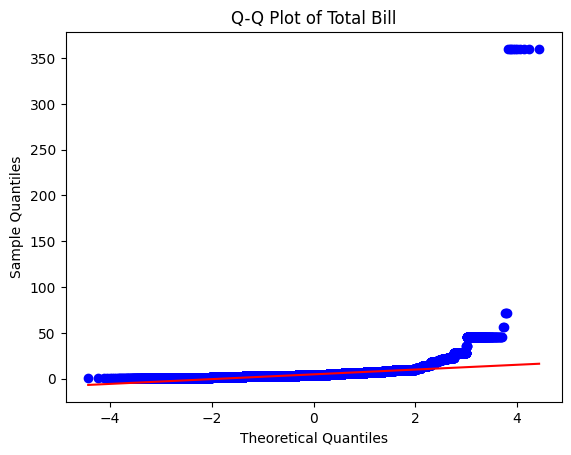

In [32]:
stats.probplot(order_amount, dist="norm", plot=plt)
plt.title("Q-Q Plot of Total Bill")
plt.xlabel("Theoretical Quantiles")
plt.ylabel("Sample Quantiles")
plt.show()


BAR CHART: total revenue for each product category

product_category
Coffee                269952.45
Tea                   196405.95
Bakery                 82315.64
Drinking Chocolate     72416.00
Coffee beans           40085.25
Branded                13607.00
Loose Tea              11213.60
Flavours                8408.80
Packaged Chocolate      4407.64
Name: Total_Bill, dtype: float64


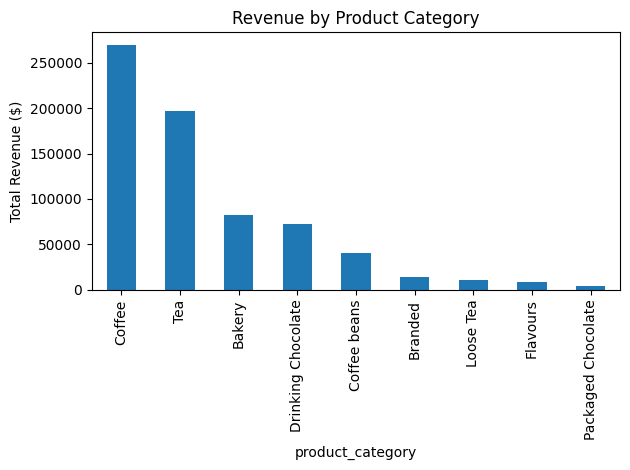

In [33]:
# Step 1: total revenue for each category
category_revenue = df.groupby("product_category")["Total_Bill"].sum()

# Step 2: arrange from highest to lowest
category_revenue = category_revenue.sort_values(ascending=False)

# Step 3: print the revenue
print(category_revenue)

# Step 4: create a bar chart
category_revenue.plot(kind="bar")

# Step 5: title and y-axis label
plt.title("Revenue by Product Category")
plt.ylabel("Total Revenue ($)")

# Step 6: show the plot
plt.tight_layout()
plt.show()


LINE CHART: bill amount in order of transactions (first 500)

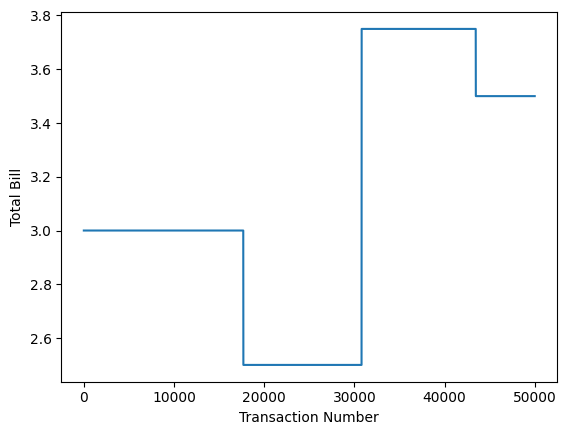

In [35]:
plt.plot(df["Total_Bill"].head(50000))
plt.xlabel("Transaction Number")
plt.ylabel("Total Bill")
plt.show()


LINE CHART: bill amount by date (daily sales)

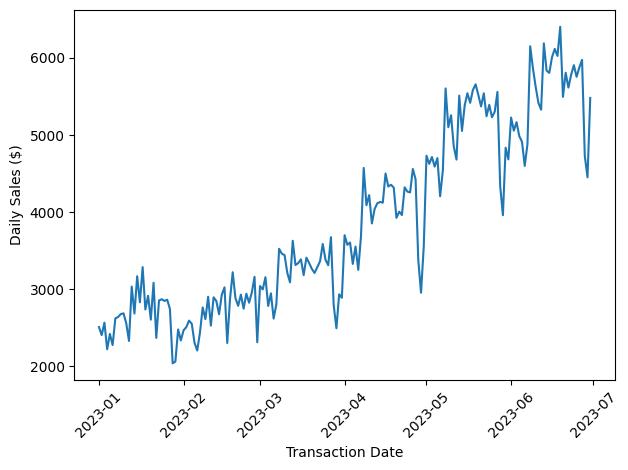

In [36]:
daily_sales = df.groupby("transaction_date")["Total_Bill"].sum()
plt.plot(daily_sales.index, daily_sales.values)
plt.xlabel("Transaction Date")
plt.ylabel("Daily Sales ($)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


PIE CHART: share of each product category

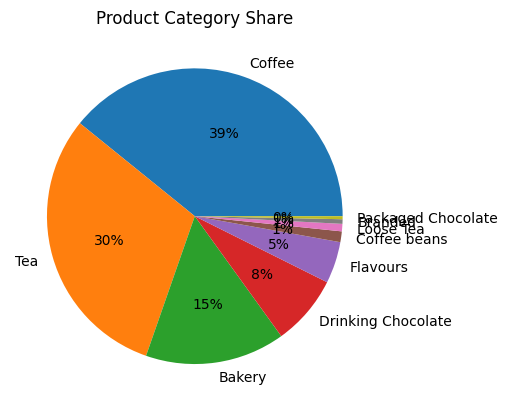

In [37]:
category_counts = df["product_category"].value_counts()
plt.pie(category_counts.values, labels=category_counts.index, autopct="%1.0f%%")
plt.title("Product Category Share")
plt.show()


HISTOGRAM: distribution of bill amounts

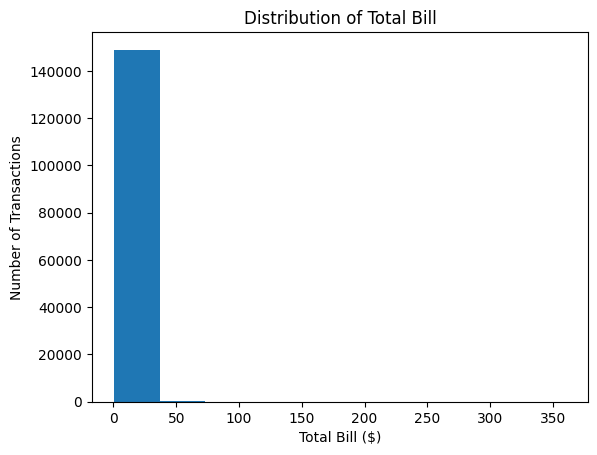

In [40]:
plt.hist(df["Total_Bill"].dropna(), bins=10)
plt.title("Distribution of Total Bill")
plt.xlabel("Total Bill ($)")
plt.ylabel("Number of Transactions")
plt.show()


PIE CHART (practice): share of each cup size

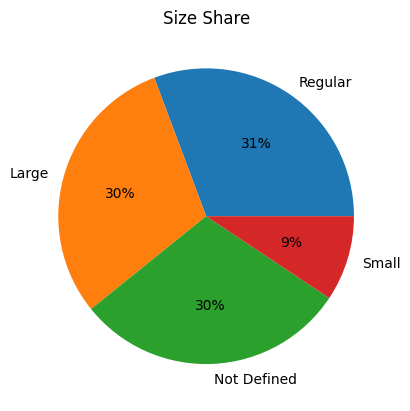

In [41]:
size_counts = df["Size"].value_counts()
plt.pie(size_counts.values, labels=size_counts.index, autopct="%1.0f%%")
plt.title("Size Share")
plt.show()


PIE CHART (practice): share of each store location

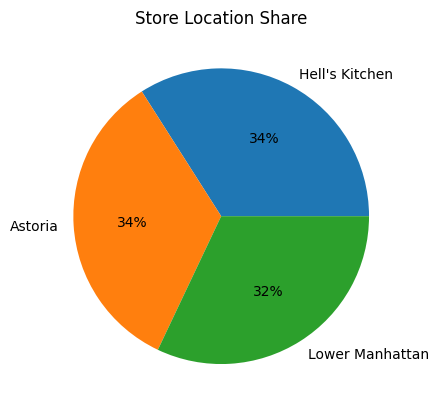

In [42]:
store_counts = df["store_location"].value_counts()
plt.pie(store_counts.values, labels=store_counts.index, autopct="%1.0f%%")
plt.title("Store Location Share")
plt.show()


#DATA CLEANING AND DATA MANIPULATION (Case: Coffee Sales)

Load the raw data (Method 1)

In [44]:
import pandas as pd
file_path = "/content/DAP Coffee Sales Dataset.xlsx"
df = pd.read_excel(file_path, sheet_name="Project")
df.head()


,transaction_id,transaction_date,transaction_time,store_id,store_location,product_id,transaction_qty,unit_price,Total_Bill,product_category,product_type,product_detail,Size,Month Name,Day Name,Hour,Month,Day of Week
0,114301,2023-06-01,11:33:29,3,Astoria,45,1,3.0,3.0,Tea,Brewed herbal tea,Peppermint,Large,June,Thursday,11,6,3
1,115405,2023-06-02,11:18:24,3,Astoria,45,1,3.0,3.0,Tea,Brewed herbal tea,Peppermint,Large,June,Friday,11,6,4
2,115478,2023-06-02,12:02:45,3,Astoria,45,1,3.0,3.0,Tea,Brewed herbal tea,Peppermint,Large,June,Friday,12,6,4
3,116288,2023-06-02,19:39:47,3,Astoria,45,1,3.0,3.0,Tea,Brewed herbal tea,Peppermint,Large,June,Friday,19,6,4
4,116714,2023-06-03,12:24:57,3,Astoria,45,1,3.0,3.0,Tea,Brewed herbal tea,Peppermint,Large,June,Saturday,12,6,5


Method 2: raw copy and the numeric columns we will study

In [46]:
raw = pd.read_excel("/content/DAP Coffee Sales Dataset.xlsx", sheet_name="Project")

num_cols = ["transaction_qty", "unit_price", "Total_Bill", "Hour"]

print("Rows and Columns:", raw.shape)
raw.head()


Rows and Columns: (149116, 18)


,transaction_id,transaction_date,transaction_time,store_id,store_location,product_id,transaction_qty,unit_price,Total_Bill,product_category,product_type,product_detail,Size,Month Name,Day Name,Hour,Month,Day of Week
0,114301,2023-06-01,11:33:29,3,Astoria,45,1,3.0,3.0,Tea,Brewed herbal tea,Peppermint,Large,June,Thursday,11,6,3
1,115405,2023-06-02,11:18:24,3,Astoria,45,1,3.0,3.0,Tea,Brewed herbal tea,Peppermint,Large,June,Friday,11,6,4
2,115478,2023-06-02,12:02:45,3,Astoria,45,1,3.0,3.0,Tea,Brewed herbal tea,Peppermint,Large,June,Friday,12,6,4
3,116288,2023-06-02,19:39:47,3,Astoria,45,1,3.0,3.0,Tea,Brewed herbal tea,Peppermint,Large,June,Friday,19,6,4
4,116714,2023-06-03,12:24:57,3,Astoria,45,1,3.0,3.0,Tea,Brewed herbal tea,Peppermint,Large,June,Saturday,12,6,5


Info of the raw data

In [47]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149116 entries, 0 to 149115
Data columns (total 18 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   transaction_id    149116 non-null  int64         
 1   transaction_date  149116 non-null  datetime64[ns]
 2   transaction_time  149116 non-null  object        
 3   store_id          149116 non-null  int64         
 4   store_location    149116 non-null  object        
 5   product_id        149116 non-null  int64         
 6   transaction_qty   149116 non-null  int64         
 7   unit_price        149116 non-null  float64       
 8   Total_Bill        149116 non-null  float64       
 9   product_category  149116 non-null  object        
 10  product_type      149116 non-null  object        
 11  product_detail    149116 non-null  object        
 12  Size              149116 non-null  object        
 13  Month Name        149116 non-null  object        
 14  Day 

Unusual values in a business dataset: blank cells

In [48]:
raw.isnull().sum()
total_blank = raw.isnull().sum().sum()
print("Blank cells:", total_blank)
print("Blank%:", round(total_blank / raw.size * 100, 1), "%")
print("Rows with at least one blank:", raw.isnull().any(axis=1).sum(), "out of", len(raw))


Blank cells: 0
Blank%: 0.0 %
Rows with at least one blank: 0 out of 149116


Blank cells heat map

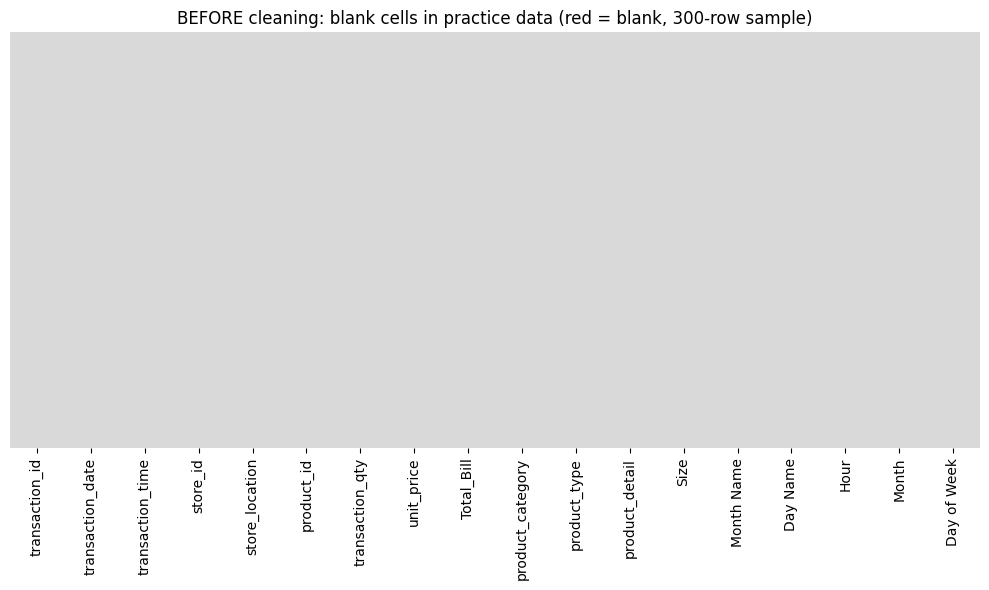

In [50]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import seaborn as sns

colors = ListedColormap(["#d9d9d9", "#d62728"])

plt.figure(figsize=(10, 6))
sns.heatmap(raw.sample(300, random_state=1).isnull(), cmap=colors, cbar=False, yticklabels=False)
plt.title("BEFORE cleaning: blank cells in practice data (red = blank, 300-row sample)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

Descriptive statistics: spot values that look wrong

In [52]:
raw[num_cols].describe().round(1)

,transaction_qty,unit_price,Total_Bill,Hour
count,149116.0,149116.0,149116.0,149116.0
mean,1.4,3.4,4.7,11.7
std,0.5,2.7,4.2,3.8
min,1.0,0.8,0.8,6.0
25%,1.0,2.5,3.0,9.0
50%,1.0,3.0,3.8,11.0
75%,2.0,3.8,6.0,15.0
max,8.0,45.0,360.0,20.0


A big gap between mean and median is a warning sign

In [55]:
gap = pd.DataFrame({
    "Mean": raw[num_cols].mean(),
    "Median": raw[num_cols].median(),
})

gap["Gap %"] = ((gap["Mean"] - gap["Median"]) / gap["Median"]) * 100

gap.round(1)

,Mean,Median,Gap %
transaction_qty,1.4,1.0,43.8
unit_price,3.4,3.0,12.7
Total_Bill,4.7,3.8,25.0
Hour,11.7,11.0,6.7


STEP 1: set up rules for each variable

In [56]:
rules = {
    "transaction_qty": (1, 10),    # a customer buys 1 to 10 items
    "unit_price": (0.5, 50),       # price of one item in dollars
    "Total_Bill": (0.5, 500),      # bill = qty x price
    "Hour": (6, 22),               # shops open from 6 am to 10 pm
}

for col, (low, high) in rules.items():
    bad = raw[(raw[col] < low) | (raw[col] > high)]
    print(col, "-> impossible values:", len(bad))
    if len(bad) > 0:
        print(bad[["transaction_date", "transaction_id", col]].head().to_string(index=False))
    print()


transaction_qty -> impossible values: 0

unit_price -> impossible values: 0

Total_Bill -> impossible values: 0

Hour -> impossible values: 0



STEP 2: time series plot (daily average, BEFORE cleaning)

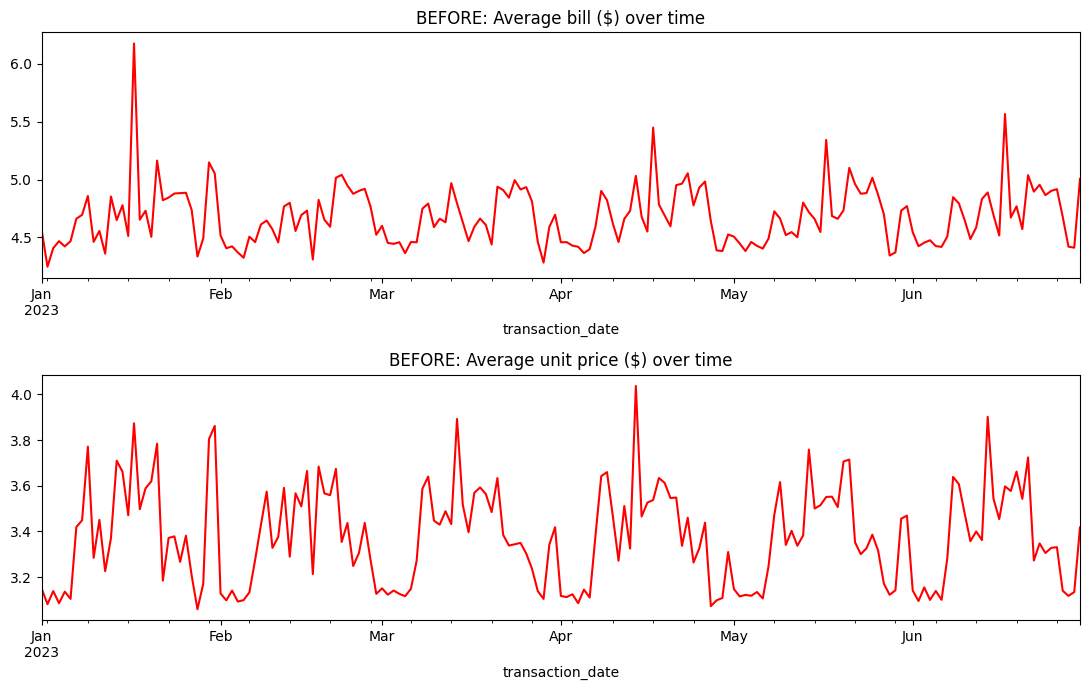

In [57]:
ts_raw = raw.set_index("transaction_date")
fig, axes = plt.subplots(2, 1, figsize=(11, 7))

ts_raw["Total_Bill"].resample("D").mean().plot(ax=axes[0], color="red", title="BEFORE: Average bill ($) over time")
ts_raw["unit_price"].resample("D").mean().plot(ax=axes[1], color="red", title="BEFORE: Average unit price ($) over time")

plt.tight_layout()
plt.show()


Boxplot of every numeric variable

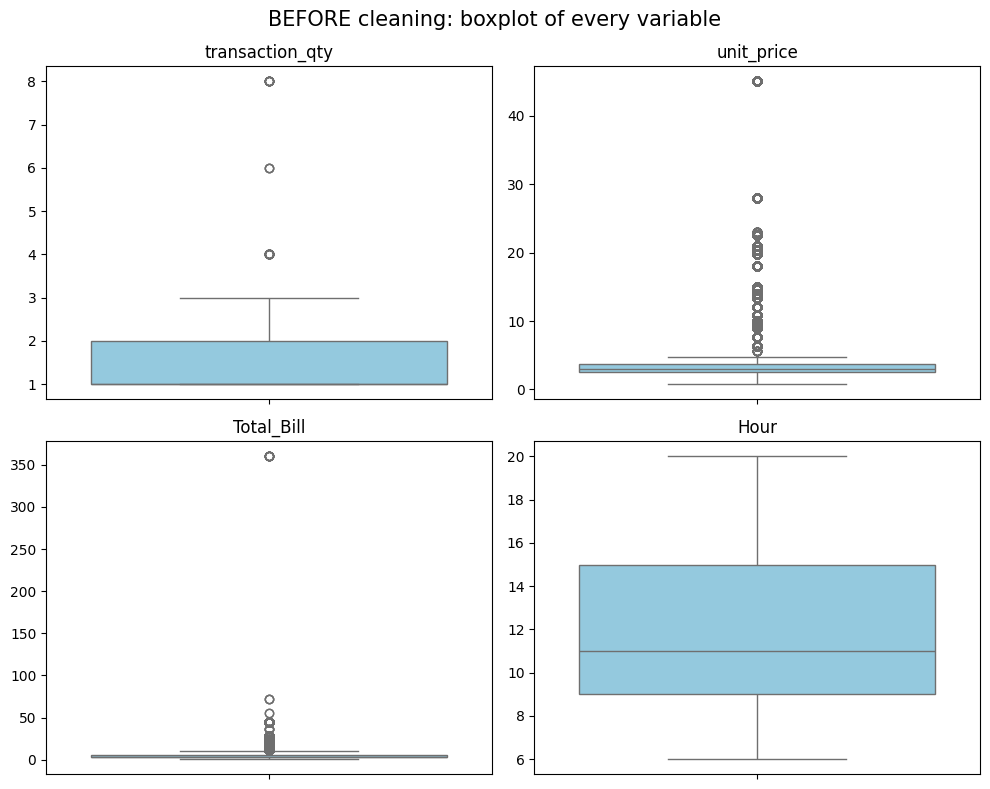

In [59]:
def show_boxplots(data, title):
    fig, axes = plt.subplots(2, 2, figsize=(10, 8))
    axes = axes.flatten()
    for i, col in enumerate(num_cols):
        sns.boxplot(y=data[col], ax=axes[i], color="skyblue")
        axes[i].set_title(col)
        axes[i].set_ylabel("")
    fig.suptitle(title, fontsize=15)
    plt.tight_layout()
    plt.show()

show_boxplots(raw, "BEFORE cleaning: boxplot of every variable")

STEP 3: retaining, removing and capping the data

In [60]:
raw[raw["Total_Bill"] > 100].head(10)

,transaction_id,transaction_date,transaction_time,store_id,store_location,product_id,transaction_qty,unit_price,Total_Bill,product_category,product_type,product_detail,Size,Month Name,Day Name,Hour,Month,Day of Week
149082,9340,2023-01-17,09:05:20,8,Hell's Kitchen,8,8,45.0,360.0,Coffee beans,Premium Beans,Civet Cat,Not Defined,January,Tuesday,9,1,1
149083,9395,2023-01-17,09:55:47,8,Hell's Kitchen,8,8,45.0,360.0,Coffee beans,Premium Beans,Civet Cat,Not Defined,January,Tuesday,9,1,1
149096,68976,2023-04-17,09:55:47,8,Hell's Kitchen,8,8,45.0,360.0,Coffee beans,Premium Beans,Civet Cat,Not Defined,April,Monday,9,4,0
149097,69151,2023-04-17,11:18:31,8,Hell's Kitchen,8,8,45.0,360.0,Coffee beans,Premium Beans,Civet Cat,Not Defined,April,Monday,11,4,0
149103,98233,2023-05-17,09:05:20,8,Hell's Kitchen,8,8,45.0,360.0,Coffee beans,Premium Beans,Civet Cat,Not Defined,May,Wednesday,9,5,2
149104,98529,2023-05-17,11:18:31,8,Hell's Kitchen,8,8,45.0,360.0,Coffee beans,Premium Beans,Civet Cat,Not Defined,May,Wednesday,11,5,2
149112,133523,2023-06-17,09:55:47,8,Hell's Kitchen,8,8,45.0,360.0,Coffee beans,Premium Beans,Civet Cat,Not Defined,June,Saturday,9,6,5
149113,133674,2023-06-17,10:41:11,8,Hell's Kitchen,8,8,45.0,360.0,Coffee beans,Premium Beans,Civet Cat,Not Defined,June,Saturday,10,6,5
149114,133744,2023-06-17,11:18:31,8,Hell's Kitchen,8,8,45.0,360.0,Coffee beans,Premium Beans,Civet Cat,Not Defined,June,Saturday,11,6,5
149115,149043,2023-06-30,11:18:31,8,Hell's Kitchen,8,8,45.0,360.0,Coffee beans,Premium Beans,Civet Cat,Not Defined,June,Friday,11,6,4


STEP 4: removing impossible values (turn them into blanks)

In [62]:
import numpy as np

# Create a copy using 'raw' instead of 'raw_blank'
df = raw.copy()

# Find quantities below 1 or above 10
bad_values = (df["transaction_qty"] < 1) | (df["transaction_qty"] > 10)

# Count unusual quantities
print("Unusual quantities:", bad_values.sum())

# Replace unusual quantities with missing values
df.loc[bad_values, "transaction_qty"] = np.nan

# Compare missing cells
print("Missing cells before:", raw.isnull().sum().sum())
print("Missing cells after:", df.isnull().sum().sum())

Unusual quantities: 0
Missing cells before: 0
Missing cells after: 0


STEP 5: capping (handling outliers) with the IQR rule

Maximum before: 360.0
Maximum after: 10.5
Upper limit: 10.5


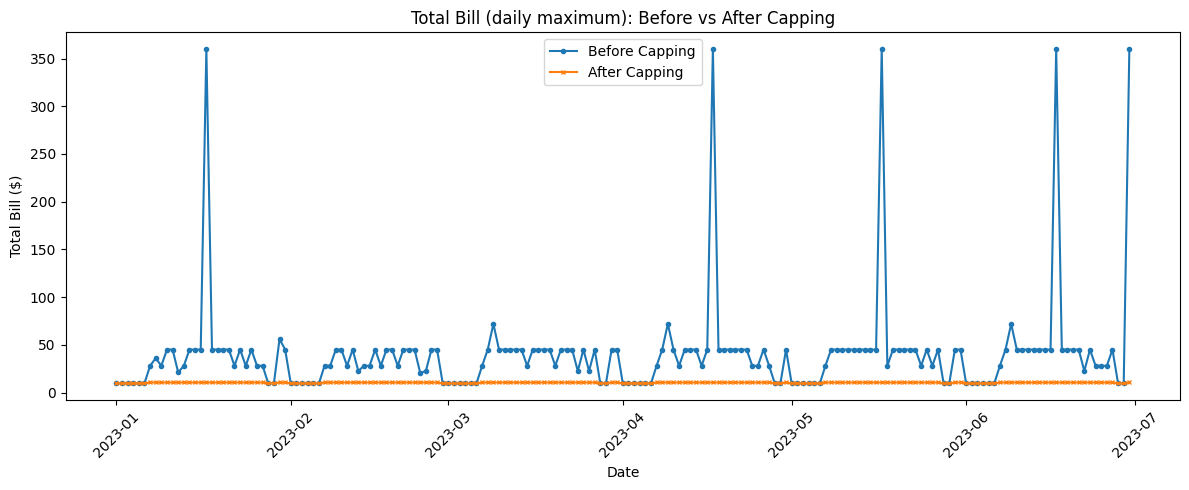

In [63]:
col = "Total_Bill"

# Start with the original, uncapped data
before = raw[col].copy()

# Fresh dataset for capping
df_capped = raw.copy()

# Q1, Q3 and IQR using original data
Q1 = before.quantile(0.25)
Q3 = before.quantile(0.75)
IQR = Q3 - Q1

# Upper and lower limits
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Apply capping to the new dataset
df_capped[col] = before.clip(lower, upper)

# Print maximum values
print("Maximum before:", before.max())
print("Maximum after:", df_capped[col].max())
print("Upper limit:", upper)

# Plot before and after (daily average)
plt.figure(figsize=(12, 5))
plt.plot(raw.groupby("transaction_date")[col].max(), label="Before Capping", marker="o", markersize=3)
plt.plot(df_capped.groupby("transaction_date")[col].max(), label="After Capping", marker="x", markersize=3)
plt.title("Total Bill (daily maximum): Before vs After Capping")
plt.xlabel("Date")
plt.ylabel("Total Bill ($)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


#MISSING VALUE TREATMENT: DROP, MEAN, MODE, MEDIAN

Flagged by IQR but possible: we leave these values unchanged

In [64]:
# Examples we keep: big bills for bulk orders of coffee beans / branded items
df[(df["transaction_qty"] >= 6) | (df["Total_Bill"] > 100)][
    ["transaction_date", "product_category", "transaction_qty", "Total_Bill"]
].head(10)


,transaction_date,product_category,transaction_qty,Total_Bill
149082,2023-01-17,Coffee beans,8.0,360.0
149083,2023-01-17,Coffee beans,8.0,360.0
149091,2023-03-09,Branded,6.0,72.0
149095,2023-04-09,Branded,6.0,72.0
149096,2023-04-17,Coffee beans,8.0,360.0
149097,2023-04-17,Coffee beans,8.0,360.0
149103,2023-05-17,Coffee beans,8.0,360.0
149104,2023-05-17,Coffee beans,8.0,360.0
149110,2023-06-09,Branded,6.0,72.0
149112,2023-06-17,Coffee beans,8.0,360.0


METHOD 1: DROP the values (dropna)

In [65]:
df_drop = df.dropna()

print("DESCRIPTIVE STATISTICS BEFORE dropna()")
print(df.describe().round(2))

print("DESCRIPTIVE STATISTICS AFTER dropna()")
print(df_drop.describe().round(2))

print("Rows before:", len(df))
print("Rows after :", len(df_drop))
print("Data lost:", round((1 - len(df_drop) / len(df)) * 100, 1), "%")

print("Missing values after dropna():")
print(df_drop.isnull().sum())
print("Total blank cells:", df_drop.isnull().sum().sum())


DESCRIPTIVE STATISTICS BEFORE dropna()
       transaction_id               transaction_date   store_id  product_id  \
count       149116.00                         149116  149116.00   149116.00   
mean         74737.37  2023-04-15 11:50:32.173609984       5.34       47.92   
min              1.00            2023-01-01 00:00:00       3.00        1.00   
25%          37335.75            2023-03-06 00:00:00       3.00       33.00   
50%          74727.50            2023-04-24 00:00:00       5.00       47.00   
75%         112094.25            2023-05-30 00:00:00       8.00       60.00   
max         149456.00            2023-06-30 00:00:00       8.00       87.00   
std          43153.60                            NaN       2.07       17.93   

       transaction_qty  unit_price  Total_Bill       Hour      Month  \
count        149116.00   149116.00   149116.00  149116.00  149116.00   
mean              1.44        3.38        4.69      11.74       3.99   
min               1.00        0.8

METHOD 2: IMPUTATION WITH MEAN

In [66]:
df_mean = df.copy()

print("DESCRIPTIVE STATISTICS BEFORE IMPUTATION")
print(df.describe().round(2))

# Numeric columns: fill with the mean
df_mean[num_cols] = df_mean[num_cols].fillna(df_mean[num_cols].mean())

# Text column: fill with the most common value (mode)
df_mean["store_location"] = df_mean["store_location"].fillna(df_mean["store_location"].mode()[0])

print("DESCRIPTIVE STATISTICS AFTER MEAN AND MODE IMPUTATION")
print(df_mean.describe().round(2))

print("Rows before:", len(df))
print("Rows after :", len(df_mean))
print("Blanks left:", df_mean.isnull().sum().sum())


DESCRIPTIVE STATISTICS BEFORE IMPUTATION
       transaction_id               transaction_date   store_id  product_id  \
count       149116.00                         149116  149116.00   149116.00   
mean         74737.37  2023-04-15 11:50:32.173609984       5.34       47.92   
min              1.00            2023-01-01 00:00:00       3.00        1.00   
25%          37335.75            2023-03-06 00:00:00       3.00       33.00   
50%          74727.50            2023-04-24 00:00:00       5.00       47.00   
75%         112094.25            2023-05-30 00:00:00       8.00       60.00   
max         149456.00            2023-06-30 00:00:00       8.00       87.00   
std          43153.60                            NaN       2.07       17.93   

       transaction_qty  unit_price  Total_Bill       Hour      Month  \
count        149116.00   149116.00   149116.00  149116.00  149116.00   
mean              1.44        3.38        4.69      11.74       3.99   
min               1.00        0

METHOD 3: IMPUTATION WITH MODE

In [67]:
df_mode = df.copy()

for col in df_mode.columns:
    if df_mode[col].isnull().any():
        df_mode[col] = df_mode[col].fillna(df_mode[col].mode()[0])

print("DESCRIPTIVE STATISTICS AFTER MODE IMPUTATION")
print(df_mode.describe().round(2))

print("Blanks left:", df_mode.isnull().sum().sum())


DESCRIPTIVE STATISTICS AFTER MODE IMPUTATION
       transaction_id               transaction_date   store_id  product_id  \
count       149116.00                         149116  149116.00   149116.00   
mean         74737.37  2023-04-15 11:50:32.173609984       5.34       47.92   
min              1.00            2023-01-01 00:00:00       3.00        1.00   
25%          37335.75            2023-03-06 00:00:00       3.00       33.00   
50%          74727.50            2023-04-24 00:00:00       5.00       47.00   
75%         112094.25            2023-05-30 00:00:00       8.00       60.00   
max         149456.00            2023-06-30 00:00:00       8.00       87.00   
std          43153.60                            NaN       2.07       17.93   

       transaction_qty  unit_price  Total_Bill       Hour      Month  \
count        149116.00   149116.00   149116.00  149116.00  149116.00   
mean              1.44        3.38        4.69      11.74       3.99   
min               1.00     

METHOD 4: IMPUTATION WITH MEDIAN

In [68]:
df_median = df.copy()
df_median[num_cols] = df_median[num_cols].fillna(df_median[num_cols].median())

# store_location is text, so use the most common value
df_median["store_location"] = df_median["store_location"].fillna(df_median["store_location"].mode()[0])

print("DESCRIPTIVE STATISTICS AFTER MEDIAN IMPUTATION")
print(df_median.describe().round(2))

print("Blanks left:", df_median.isnull().sum().sum())


DESCRIPTIVE STATISTICS AFTER MEDIAN IMPUTATION
       transaction_id               transaction_date   store_id  product_id  \
count       149116.00                         149116  149116.00   149116.00   
mean         74737.37  2023-04-15 11:50:32.173609984       5.34       47.92   
min              1.00            2023-01-01 00:00:00       3.00        1.00   
25%          37335.75            2023-03-06 00:00:00       3.00       33.00   
50%          74727.50            2023-04-24 00:00:00       5.00       47.00   
75%         112094.25            2023-05-30 00:00:00       8.00       60.00   
max         149456.00            2023-06-30 00:00:00       8.00       87.00   
std          43153.60                            NaN       2.07       17.93   

       transaction_qty  unit_price  Total_Bill       Hour      Month  \
count        149116.00   149116.00   149116.00  149116.00  149116.00   
mean              1.44        3.38        4.69      11.74       3.99   
min               1.00   

HEAT PLOTS AFTER TREATMENT

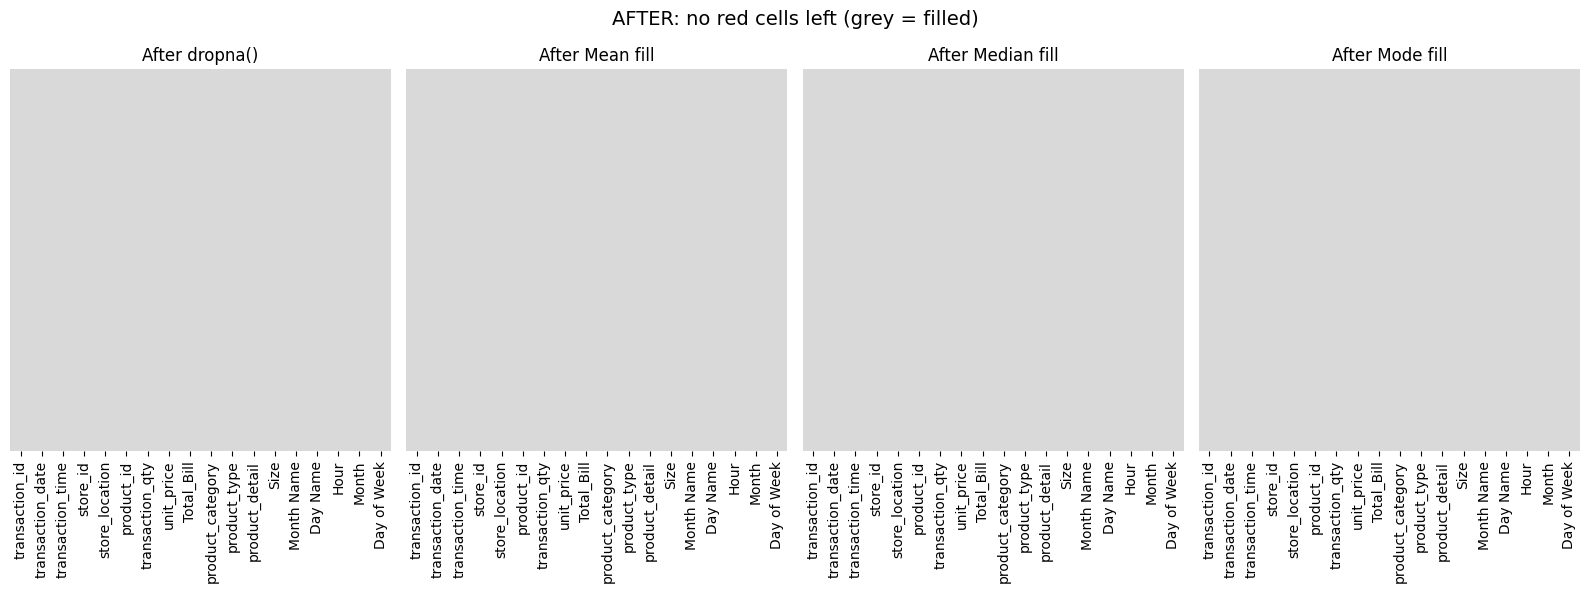

In [71]:
fig, axes = plt.subplots(1, 4, figsize=(16, 6))

sns.heatmap(df_drop.sample(300, random_state=1).isnull(), cmap=colors, cbar=False, yticklabels=False, ax=axes[0])
axes[0].set_title("After dropna()")

sns.heatmap(df_mean.sample(300, random_state=1).isnull(), cmap=colors, cbar=False, yticklabels=False, ax=axes[1])
axes[1].set_title("After Mean fill")

sns.heatmap(df_median.sample(300, random_state=1).isnull(), cmap=colors, cbar=False, yticklabels=False, ax=axes[2])
axes[2].set_title("After Median fill")

sns.heatmap(df_mode.sample(300, random_state=1).isnull(), cmap=colors, cbar=False, yticklabels=False, ax=axes[3])
axes[3].set_title("After Mode fill")

plt.suptitle("AFTER: no red cells left (grey = filled)", fontsize=14)
plt.tight_layout()
plt.show()


BOXPLOT AFTER IMPUTATION

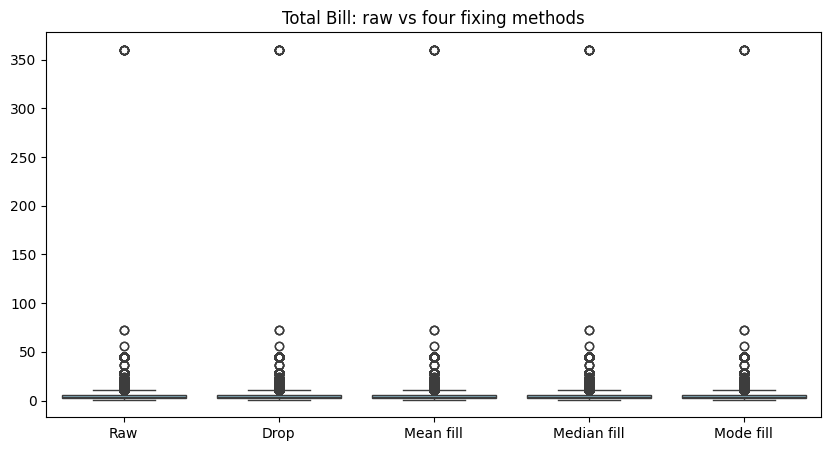

149115    360.0
149097    360.0
149113    360.0
149096    360.0
149112    360.0
149082    360.0
149083    360.0
149103    360.0
149104    360.0
149114    360.0
Name: Total_Bill, dtype: float64


In [73]:
bill_compare = pd.DataFrame({
    "Raw": raw["Total_Bill"],
    "Drop": df_drop["Total_Bill"],
    "Mean fill": df_mean["Total_Bill"],
    "Median fill": df_median["Total_Bill"],
    "Mode fill": df_mode["Total_Bill"],
})

plt.figure(figsize=(10, 5))
sns.boxplot(data=bill_compare, color="skyblue")
plt.title("Total Bill: raw vs four fixing methods")
plt.show()

# Check the largest bill values
print(raw["Total_Bill"].sort_values(ascending=False).head(10))

DESCRIPTION OF CLEANED DATA (final = Median Imputation)

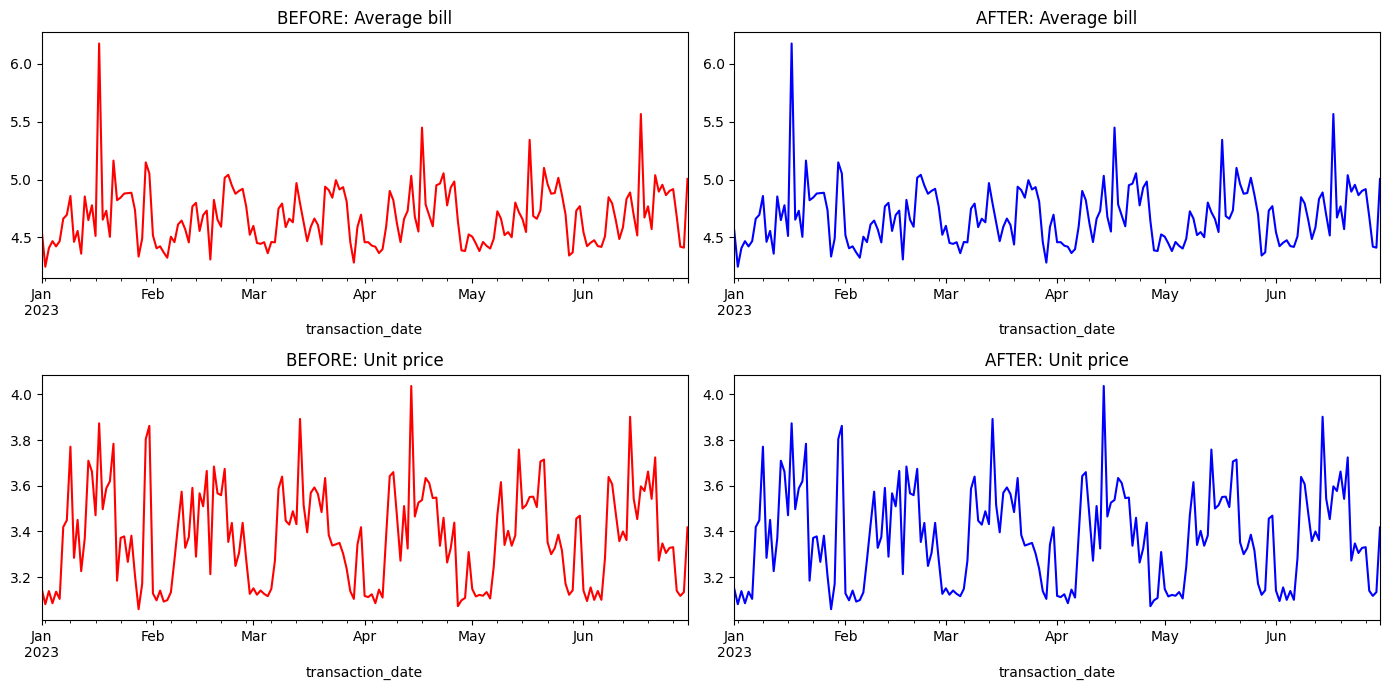

In [74]:
final = df_median.copy()

# BEFORE vs AFTER time series
ts_final = final.set_index("transaction_date")
fig, axes = plt.subplots(2, 2, figsize=(14, 7))

ts_raw["Total_Bill"].resample("D").mean().plot(ax=axes[0, 0], color="red", title="BEFORE: Average bill")
ts_final["Total_Bill"].resample("D").mean().plot(ax=axes[0, 1], color="blue", title="AFTER: Average bill")

ts_raw["unit_price"].resample("D").mean().plot(ax=axes[1, 0], color="red", title="BEFORE: Unit price")
ts_final["unit_price"].resample("D").mean().plot(ax=axes[1, 1], color="blue", title="AFTER: Unit price")

plt.tight_layout()
plt.show()


#ADVANCED DATA VISUALISATION



In [76]:
import pandas as pd
import numpy as np

df = pd.read_excel("/content/DAP Coffee Sales Dataset.xlsx", sheet_name="Project")

print("Rows:", df.shape[0], "| Columns:", df.shape[1])
df.head()


Rows: 149116 | Columns: 18


,transaction_id,transaction_date,transaction_time,store_id,store_location,product_id,transaction_qty,unit_price,Total_Bill,product_category,product_type,product_detail,Size,Month Name,Day Name,Hour,Month,Day of Week
0,114301,2023-06-01,11:33:29,3,Astoria,45,1,3.0,3.0,Tea,Brewed herbal tea,Peppermint,Large,June,Thursday,11,6,3
1,115405,2023-06-02,11:18:24,3,Astoria,45,1,3.0,3.0,Tea,Brewed herbal tea,Peppermint,Large,June,Friday,11,6,4
2,115478,2023-06-02,12:02:45,3,Astoria,45,1,3.0,3.0,Tea,Brewed herbal tea,Peppermint,Large,June,Friday,12,6,4
3,116288,2023-06-02,19:39:47,3,Astoria,45,1,3.0,3.0,Tea,Brewed herbal tea,Peppermint,Large,June,Friday,19,6,4
4,116714,2023-06-03,12:24:57,3,Astoria,45,1,3.0,3.0,Tea,Brewed herbal tea,Peppermint,Large,June,Saturday,12,6,5


First look at the data

In [77]:
df.describe().round(1)

,transaction_id,transaction_date,store_id,product_id,transaction_qty,unit_price,Total_Bill,Hour,Month,Day of Week
count,149116.0,149116,149116.0,149116.0,149116.0,149116.0,149116.0,149116.0,149116.0,149116.0
mean,74737.4,2023-04-15 11:50:32.173609984,5.3,47.9,1.4,3.4,4.7,11.7,4.0,3.0
min,1.0,2023-01-01 00:00:00,3.0,1.0,1.0,0.8,0.8,6.0,1.0,0.0
25%,37335.8,2023-03-06 00:00:00,3.0,33.0,1.0,2.5,3.0,9.0,3.0,1.0
50%,74727.5,2023-04-24 00:00:00,5.0,47.0,1.0,3.0,3.8,11.0,4.0,3.0
75%,112094.2,2023-05-30 00:00:00,8.0,60.0,2.0,3.8,6.0,15.0,5.0,5.0
max,149456.0,2023-06-30 00:00:00,8.0,87.0,8.0,45.0,360.0,20.0,6.0,6.0
std,43153.6,NaN,2.1,17.9,0.5,2.7,4.2,3.8,1.7,2.0


Number of transactions in a particular store

In [78]:
df["store_location"].value_counts()

,count
store_location,
Hell's Kitchen,50735
Astoria,50599
Lower Manhattan,47782


Prepare helper columns

In [79]:
df["transaction_date"] = pd.to_datetime(df["transaction_date"])
df["Week"] = df["transaction_date"].dt.isocalendar().week.astype(int)
df["Weekday"] = df["transaction_date"].dt.day_name()
df["Is_Weekend"] = df["Day of Week"] >= 5          # 5 = Saturday, 6 = Sunday

# Time slot of the day from the Hour column
def get_slot(h):
    if h < 12:
        return "Morning"
    elif h < 17:
        return "Afternoon"
    else:
        return "Evening"

df["Time_Slot"] = df["Hour"].apply(get_slot)

# Fixed orders so charts always show groups in a sensible order
slot_order = ["Morning", "Afternoon", "Evening"]
size_order = ["Small", "Regular", "Large", "Not Defined"]

df[["transaction_date", "Week", "Weekday", "Time_Slot", "Is_Weekend"]].head()


,transaction_date,Week,Weekday,Time_Slot,Is_Weekend
0,2023-06-01,22,Thursday,Morning,False
1,2023-06-02,22,Friday,Morning,False
2,2023-06-02,22,Friday,Afternoon,False
3,2023-06-02,22,Friday,Evening,False
4,2023-06-03,22,Saturday,Afternoon,True


Matplotlib: how big is a typical bill and how many are under $5?

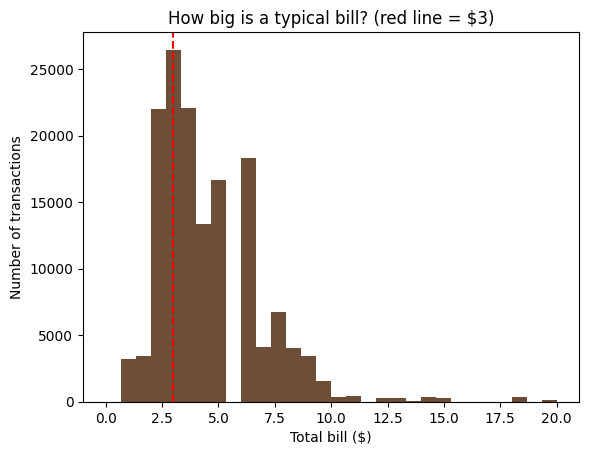

Share of bills within $3: 31.1 %


In [85]:
import matplotlib.pyplot as plt

plt.hist(df["Total_Bill"], bins=30, range=(0, 20), color="#6F4E37")
plt.axvline(3, color="red", linestyle="--")
plt.title("How big is a typical bill? (red line = $3)")
plt.xlabel("Total bill ($)")
plt.ylabel("Number of transactions")
plt.show()

df["Within_3_Dollar"] = df["Total_Bill"] <= 3
print("Share of bills within $3:", round(df["Within_3_Dollar"].mean() * 100, 1), "%")


Which product category brings the most sales?

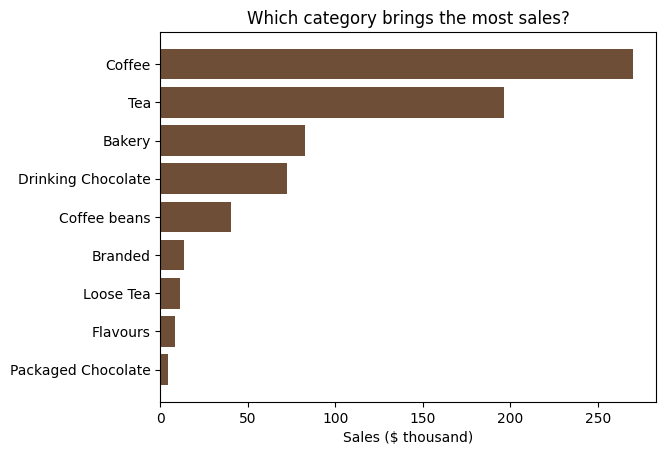

In [86]:
category_sales = df.groupby("product_category")["Total_Bill"].sum().sort_values()

plt.barh(category_sales.index, category_sales.values / 1000, color="#6F4E37")
plt.title("Which category brings the most sales?")
plt.xlabel("Sales ($ thousand)")
plt.show()


Are transactions growing week by week?

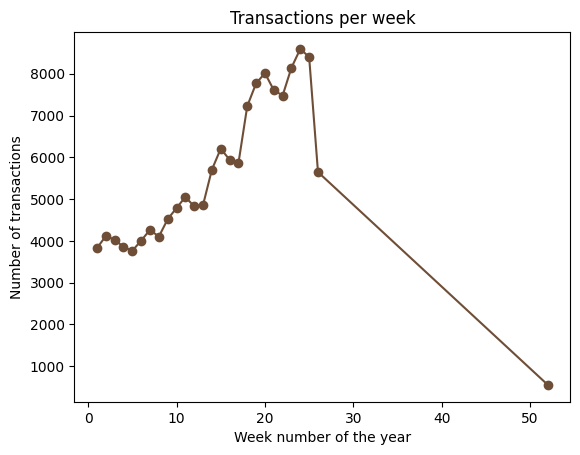

In [87]:
weekly_orders = df.groupby("Week")["transaction_id"].count()

plt.plot(weekly_orders.index, weekly_orders.values, marker="o", color="#6F4E37")
plt.title("Transactions per week")
plt.xlabel("Week number of the year")
plt.ylabel("Number of transactions")
plt.show()


AREA PLOT: which part of the day builds our weekly sales?

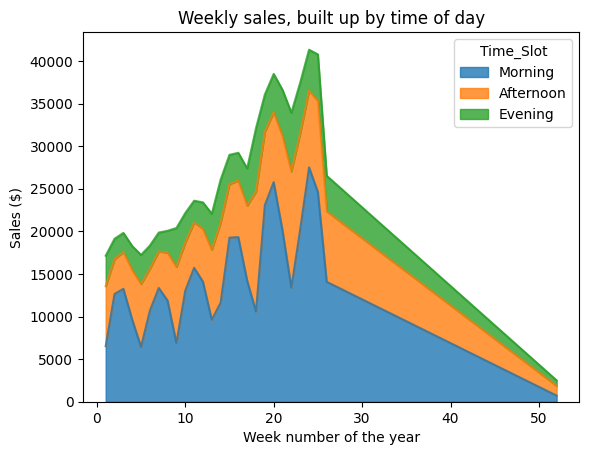

In [88]:
week_slot = df.pivot_table(index="Week", columns="Time_Slot", values="Total_Bill", aggfunc="sum")[slot_order]

week_slot.plot(kind="area", alpha=0.8)
plt.title("Weekly sales, built up by time of day")
plt.xlabel("Week number of the year")
plt.ylabel("Sales ($)")
plt.show()


SCATTER: does a higher unit price mean a bigger bill?

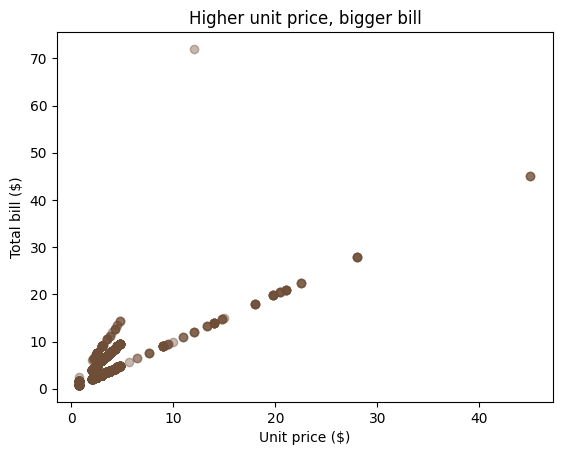

In [89]:
sample = df.sample(3000, random_state=1)

plt.scatter(sample["unit_price"], sample["Total_Bill"], alpha=0.4, color="#6F4E37")
plt.title("Higher unit price, bigger bill")
plt.xlabel("Unit price ($)")
plt.ylabel("Total bill ($)")
plt.show()


SCATTER: does buying more items mean a bigger bill?

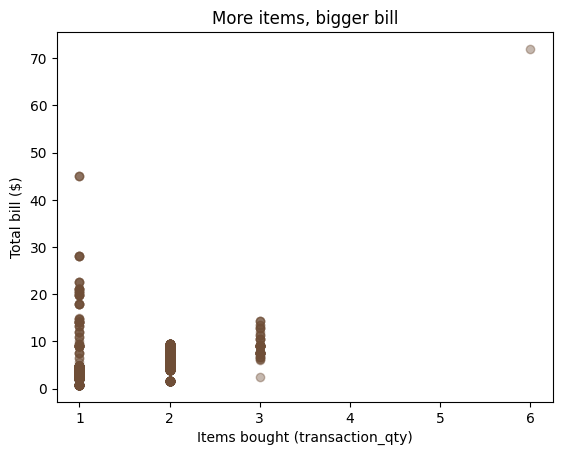

In [90]:
plt.scatter(sample["transaction_qty"], sample["Total_Bill"], alpha=0.4, color="#6F4E37")
plt.title("More items, bigger bill")
plt.xlabel("Items bought (transaction_qty)")
plt.ylabel("Total bill ($)")
plt.show()


QUIVER PLOTS: what does the weekend do to each product category?

In [92]:
means = df.groupby(["product_category", "Is_Weekend"])[["transaction_qty", "Total_Bill"]].mean().reset_index()

weekday = means[means["Is_Weekend"] == False].set_index("product_category")
weekend = means[means["Is_Weekend"] == True].set_index("product_category")

x = weekday["transaction_qty"]                              # arrow starts here (weekday)
y = weekday["Total_Bill"]
dx = weekend["transaction_qty"] - weekday["transaction_qty"]   # how far the weekend moves it
dy = weekend["Total_Bill"] - weekday["Total_Bill"]


Draw the quiver plot

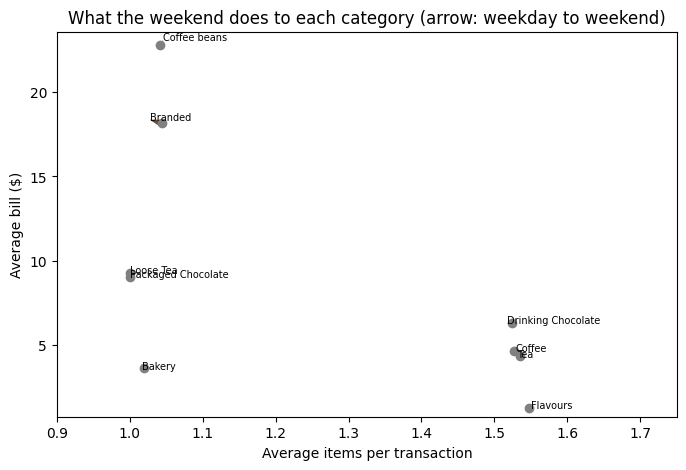

In [94]:
plt.figure(figsize=(8, 5))
plt.quiver(x, y, dx, dy, angles="xy", scale_units="xy", scale=1, color="#6F4E37")
plt.scatter(x, y, color="grey")

for name in weekday.index:
    plt.text(x[name] + dx[name], y[name] + dy[name] - 0.03, name, fontsize=7)   # label at the arrow tip
    plt.xlim(min(x.min(), (x + dx).min()) - 0.1, max(x.max(), (x + dx).max()) + 0.2)
plt.ylim(min(y.min(), (y + dy).min()) - 0.5, max(y.max(), (y + dy).max()) + 0.5)
plt.title("What the weekend does to each category (arrow: weekday to weekend)")
plt.xlabel("Average items per transaction")
plt.ylabel("Average bill ($)")
plt.show()




CONTOUR PLOT / 2D PLOTS - Step 1: developing the matrix (tiny example first)

In [95]:
price_ex = np.array([1, 2, 3])
qty_ex = np.array([5, 10])

P, Q = np.meshgrid(price_ex, qty_ex)

print(P)
print(Q)


[[1 2 3]
 [1 2 3]]
[[ 5  5  5]
 [10 10 10]]


Step 2: dividing the matrix

In [96]:
price_values = np.linspace(0.8, 10, 40)    # 40 unit prices, $0.8 to $10
qty_values = np.linspace(1, 8, 40)         # 40 basket sizes, 1 to 8 items

P, Q = np.meshgrid(price_values, qty_values)

print("Number of what-if cases:", P.size)


Number of what-if cases: 1600


Step 3: linear regression - predictions

In [97]:
from sklearn.linear_model import LinearRegression

formula = LinearRegression().fit(
    df[["unit_price", "transaction_qty"]],
    df["Total_Bill"]
)

print("Each extra $1 of unit price adds about $", round(formula.coef_[0], 2), "to the bill")
print("Each extra item adds about $", round(formula.coef_[1], 2), "to the bill")


Each extra $1 of unit price adds about $ 1.18 to the bill
Each extra item adds about $ 3.49 to the bill


Step 4: what-if case

In [98]:
cases = pd.DataFrame({
    "unit_price": P.ravel(),
    "transaction_qty": Q.ravel()
})

T = formula.predict(cases).reshape(P.shape)


Which price and basket size gives a bill of $5, $10, $15 or $20?

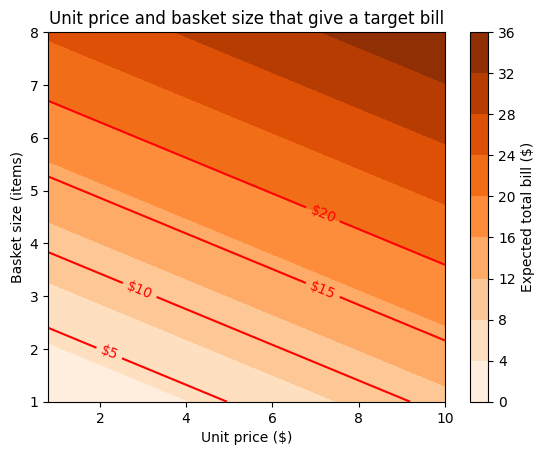

In [99]:
plt.contourf(P, Q, T, levels=10, cmap="Oranges")
plt.colorbar(label="Expected total bill ($)")

lines = plt.contour(P, Q, T, levels=[5, 10, 15, 20], colors="red")
plt.clabel(lines, fmt="$%d")

plt.title("Unit price and basket size that give a target bill")
plt.xlabel("Unit price ($)")
plt.ylabel("Basket size (items)")
plt.show()


SEABORN PLOTS AND ANIMATION

Imports and reload the data

In [100]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import seaborn as sns

df = pd.read_excel("/content/DAP Coffee Sales Dataset.xlsx", sheet_name="Project")


Animation plot: how did sales build up week by week in each store?

In [101]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML        # works in Colab / Jupyter

df["transaction_date"] = pd.to_datetime(df["transaction_date"])
df["Week"] = df["transaction_date"].dt.isocalendar().week

# Running total sales, week by week for each store
running = (df.pivot_table(index="Week", columns="store_location", values="Total_Bill", aggfunc="sum")
             .fillna(0).cumsum())
running = running[running.iloc[-1].sort_values().index]

fig, ax = plt.subplots(figsize=(7, 5))

def draw(i):
    ax.clear()
    # use the frame index i to display cumulative sales up to that week
    ax.barh(running.columns, running.iloc[i] / 1000, color="#6F4E37")
    ax.set_xlim(0, running.values.max() / 1000 * 1.1)
    ax.set_title("Sales up to week " + str(running.index[i]))
    ax.set_xlabel("Sales ($ thousand)")

anim = FuncAnimation(fig, draw, frames=len(running), interval=700)

plt.close()
HTML(anim.to_jshtml())


COUNTPLOT: what time of the day gets the most orders?

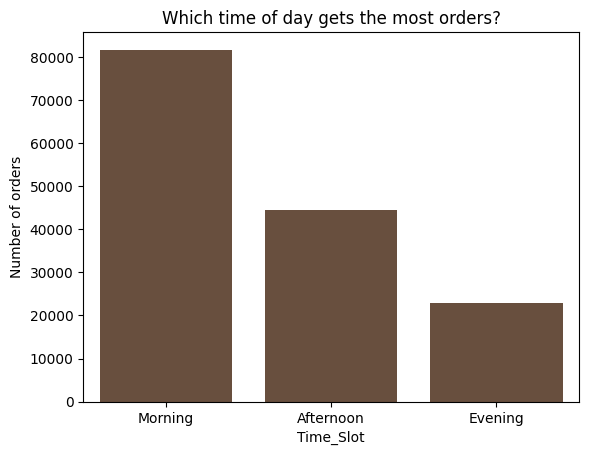

In [102]:
def get_slot(h):
    if h < 12:
        return "Morning"
    elif h < 17:
        return "Afternoon"
    else:
        return "Evening"

df["Time_Slot"] = df["Hour"].apply(get_slot)
slot_order = ["Morning", "Afternoon", "Evening"]

sns.countplot(data=df, x="Time_Slot", order=slot_order, color="#6F4E37")

plt.title("Which time of day gets the most orders?")
plt.ylabel("Number of orders")

plt.show()


COUNTPLOT with hue: which slot is the busiest for each category?

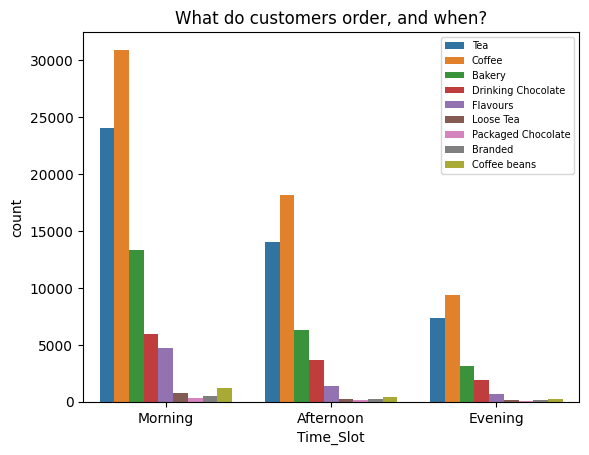

In [103]:
sns.countplot(data=df, x="Time_Slot", order=slot_order, hue="product_category")

plt.title("What do customers order, and when?")
plt.legend(fontsize=7)
plt.show()

BOXPLOT: which time slot has the biggest and least predictable bills?

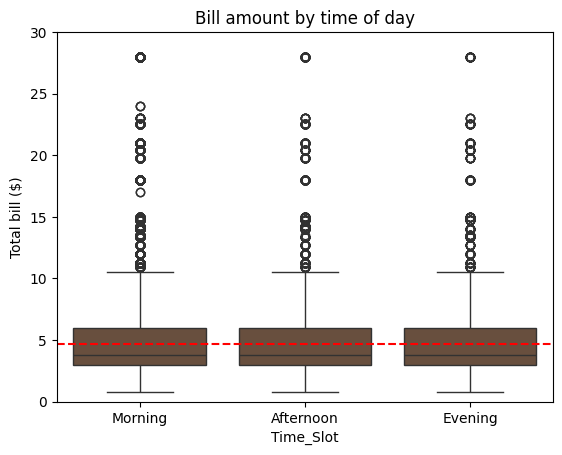

In [104]:
sns.boxplot(data=df, x="Time_Slot", y="Total_Bill", order=slot_order, color="#6F4E37")
plt.axhline(df["Total_Bill"].mean(), color="red", linestyle="--")   # overall average

plt.title("Bill amount by time of day")
plt.ylabel("Total bill ($)")
plt.ylim(0, 30)
plt.show()


VIOLIN PLOT: do different cup sizes spend differently?

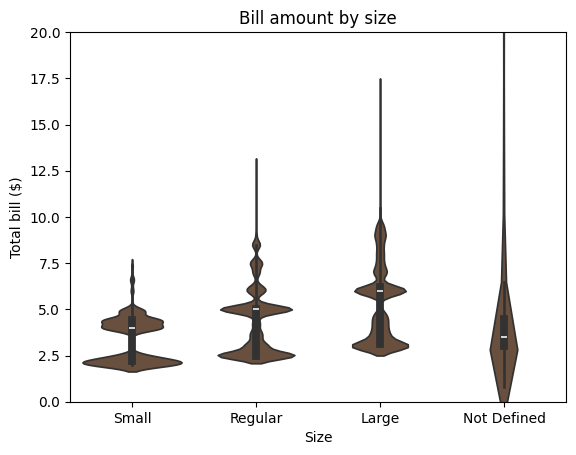

In [105]:
size_order = ["Small", "Regular", "Large", "Not Defined"]

sns.violinplot(data=df, x="Size", y="Total_Bill", order=size_order, color="#6F4E37")
plt.title("Bill amount by size")
plt.ylabel("Total bill ($)")
plt.ylim(0, 20)
plt.show()


STRIP PLOT: are high bills caused by many orders or only a few?

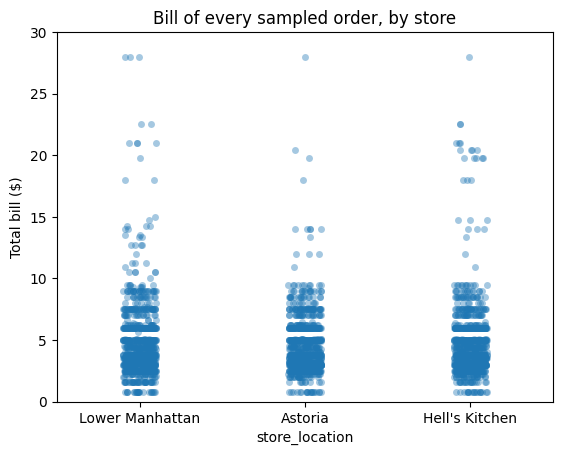

In [106]:
strip_sample = df.sample(3000, random_state=1)

sns.stripplot(data=strip_sample, x="store_location", y="Total_Bill", jitter=True, alpha=0.4)

plt.title("Bill of every sampled order, by store")
plt.ylabel("Total bill ($)")
plt.ylim(0, 30)
plt.show()


SWARM PLOT: do weekend customers really buy bigger baskets?

/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 11.4% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 47.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


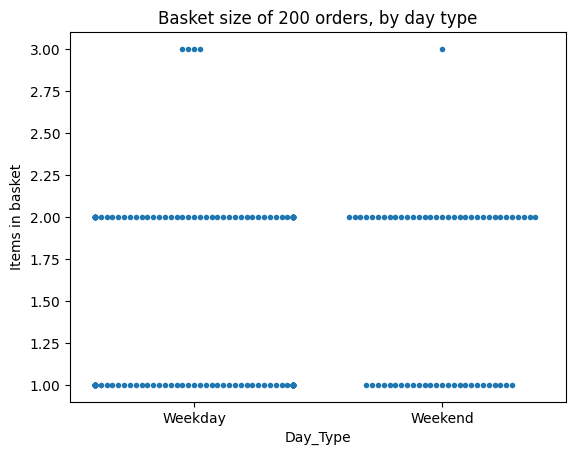

In [107]:
df["Day_Type"] = np.where(df["Day of Week"] >= 5, "Weekend", "Weekday")
swarm_sample = df.sample(200, random_state=1)

sns.swarmplot(data=swarm_sample, x="Day_Type", y="transaction_qty", order=["Weekday", "Weekend"], size=4)

plt.title("Basket size of 200 orders, by day type")
plt.ylabel("Items in basket")
plt.show()


GEOPANDAS: MAPS AND GEOGRAPHY

Step 1: importing the map  

In [108]:
import geopandas as gpd
from shapely.geometry import Point

# The three coffee stores are in New York City. Approximate store coordinates:
store_coords = {
    "Hell's Kitchen":  (40.7638, -73.9918),
    "Astoria":         (40.7644, -73.9235),
    "Lower Manhattan": (40.7075, -74.0113),
}
store_borough = {"Hell's Kitchen": "Manhattan", "Astoria": "Queens", "Lower Manhattan": "Manhattan"}

# Map of NYC boroughs (needs internet) - falls back to points only if it cannot load
try:
    url = "https://raw.githubusercontent.com/dwillis/nyc-maps/master/boroughs.geojson"
    nyc = gpd.read_file(url)
    name_col = [c for c in nyc.columns if c.lower() in ("boroname", "borough", "name")][0]
    nyc = nyc.dissolve(by=name_col, as_index=False)
    print("Boroughs on the map:", len(nyc))
except Exception as e:
    nyc = None
    print("Borough map could not be loaded, plotting store points only:", e)


Boroughs on the map: 5


Step 2: which store brings the most sales?

In [109]:
store_data = df.groupby("store_location").agg(
    Sales_K=("Total_Bill", lambda x: x.sum() / 1000),
    Avg_Bill=("Total_Bill", "mean"),
).round(2).reset_index()

store_data["Borough"] = store_data["store_location"].map(store_borough)
store_data["geometry"] = store_data["store_location"].map(lambda s: Point(store_coords[s][1], store_coords[s][0]))
store_gdf = gpd.GeoDataFrame(store_data, geometry="geometry", crs="EPSG:4326")

store_data.sort_values("Sales_K", ascending=False)


,store_location,Sales_K,Avg_Bill,Borough,geometry
1,Hell's Kitchen,236.51,4.66,Manhattan,POINT (-73.9918 40.7638)
0,Astoria,232.24,4.59,Queens,POINT (-73.9235 40.7644)
2,Lower Manhattan,230.06,4.81,Manhattan,POINT (-74.0113 40.7075)



Step 3: filling numbers in the map (sales by store)

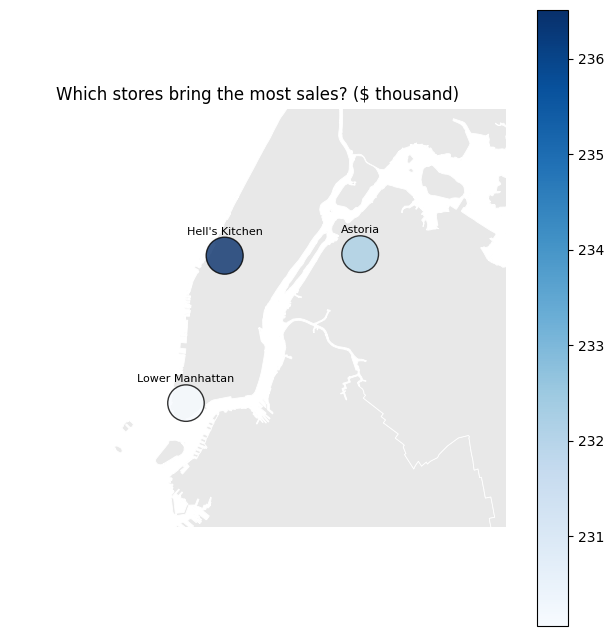

In [110]:
fig, ax = plt.subplots(figsize=(8, 8))

if nyc is not None:
    nyc.plot(ax=ax, color="#e8e8e8", edgecolor="white", linewidth=0.6)

store_gdf.plot(ax=ax, column="Sales_K", cmap="Blues", legend=True,
               markersize=store_gdf["Sales_K"] * 3, edgecolor="black", alpha=0.8)

for _, row in store_gdf.iterrows():
    ax.text(row.geometry.x, row.geometry.y + 0.008, row["store_location"], fontsize=8, ha="center")

# zoom to the stores
ax.set_xlim(-74.10, -73.85)
ax.set_ylim(40.66, 40.82)
ax.set_title("Which stores bring the most sales? ($ thousand)")
ax.axis("off")

plt.show()


Step 4: in which store is the average bill the highest?

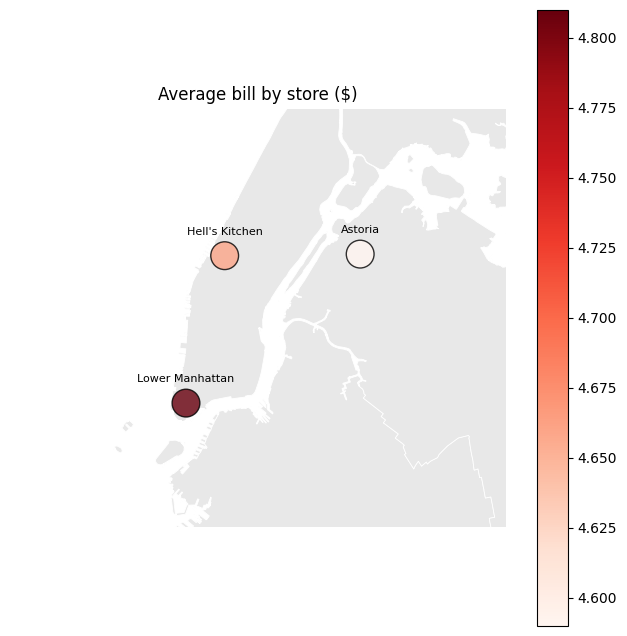

In [111]:
fig, ax = plt.subplots(figsize=(8, 8))

if nyc is not None:
    nyc.plot(ax=ax, color="#e8e8e8", edgecolor="white", linewidth=0.6)

store_gdf.plot(ax=ax, column="Avg_Bill", cmap="Reds", legend=True,
               markersize=400, edgecolor="black", alpha=0.8)

for _, row in store_gdf.iterrows():
    ax.text(row.geometry.x, row.geometry.y + 0.008, row["store_location"], fontsize=8, ha="center")

ax.set_xlim(-74.10, -73.85)
ax.set_ylim(40.66, 40.82)
ax.set_title("Average bill by store ($)")
ax.axis("off")

plt.show()


#CORRELATION AND LINEAR REGRESSION

Build a store-day dataset (one row per store per day) from the coffee file

In [113]:
import pandas as pd
import numpy as np

df = pd.read_excel("/content/DAP Coffee Sales Dataset.xlsx", sheet_name="Project")
df["transaction_date"] = pd.to_datetime(df["transaction_date"])

grp = df.groupby(["transaction_date", "store_location"])

daily = grp.agg(
    Daily_Sales=("Total_Bill", "sum"),
    Transactions=("transaction_id", "nunique"),
    Items_Sold=("transaction_qty", "sum"),
    Avg_Unit_Price=("unit_price", "mean"),
    Avg_Bill=("Total_Bill", "mean"),
    Avg_Hour=("Hour", "mean"),
    Unique_Products=("product_id", "nunique"),
).reset_index()

# Shares (in %) of each product category in the day's sales, and of morning / large-size transactions
cat_share = (df.pivot_table(index=["transaction_date", "store_location"], columns="product_category",
                            values="Total_Bill", aggfunc="sum").fillna(0))
cat_share = cat_share.div(cat_share.sum(axis=1), axis=0) * 100
cat_share = cat_share[["Coffee", "Tea", "Bakery"]].add_suffix("_Share_Pct").reset_index()

extra = grp.apply(lambda g: pd.Series({
    "Morning_Share_Pct": (g["Hour"] < 12).mean() * 100,
    "Large_Size_Share_Pct": (g["Size"] == "Large").mean() * 100,
}), include_groups=False).reset_index()

df = (daily.merge(cat_share, on=["transaction_date", "store_location"])
           .merge(extra, on=["transaction_date", "store_location"]))
df["Is_Weekend"] = (df["transaction_date"].dt.dayofweek >= 5).astype(int)

print("Store-day rows:", df.shape[0])
df.head()


Store-day rows: 543


,transaction_date,store_location,Daily_Sales,Transactions,Items_Sold,Avg_Unit_Price,Avg_Bill,Avg_Hour,Unique_Products,Coffee_Share_Pct,Tea_Share_Pct,Bakery_Share_Pct,Morning_Share_Pct,Large_Size_Share_Pct,Is_Weekend
0,2023-01-01,Astoria,868.40,190,277,3.161316,4.570526,15.000000,47,43.965914,32.600184,7.024413,11.578947,35.789474,1
1,2023-01-01,Hell's Kitchen,851.45,184,270,3.177446,4.627446,13.717391,49,50.155617,33.754184,7.663398,28.260870,38.586957,1
2,2023-01-01,Lower Manhattan,788.35,176,255,3.105114,4.479261,11.960227,51,44.555083,30.519439,14.619141,46.590909,30.113636,1
3,2023-01-02,Astoria,925.50,212,301,3.122170,4.365566,14.886792,51,46.126418,31.102107,13.749325,12.264151,32.547170,0
4,2023-01-02,Hell's Kitchen,828.80,195,272,3.072051,4.250256,13.215385,50,48.057432,33.391651,9.833494,36.410256,34.358974,0


Descriptive statistics

In [114]:
print("DESCRIPTIVE STATISTICS")
print(df.describe().round(2))

print("DATASET INFORMATION")
df.info()

print("MISSING VALUES")
print(df.isnull().sum())

print("MEAN")
print(df.mean(numeric_only=True).round(2))

print("MEDIAN")
print(df.median(numeric_only=True).round(2))

print("MODE")
print(df.mode().head(1))


DESCRIPTIVE STATISTICS
          transaction_date  Daily_Sales  Transactions  Items_Sold  \
count                  543       543.00        543.00      543.00   
mean   2023-04-01 00:00:00      1286.95        274.62      394.97   
min    2023-01-01 00:00:00       604.20        135.00      195.00   
25%    2023-02-15 00:00:00       929.68        202.00      289.50   
50%    2023-04-01 00:00:00      1165.33        257.00      364.00   
75%    2023-05-16 00:00:00      1611.43        347.00      496.00   
max    2023-06-30 00:00:00      2546.43        498.00      770.00   
std                    NaN       430.80         88.13      130.49   

       Avg_Unit_Price  Avg_Bill  Avg_Hour  Unique_Products  Coffee_Share_Pct  \
count          543.00    543.00    543.00           543.00            543.00   
mean             3.38      4.69     11.74            58.50             38.89   
min              2.82      3.71      8.70            44.00             16.87   
25%              3.14      4.42    

Which business variables do we want to relate and what are their types?

In [115]:
numbers = df.select_dtypes(include="number").columns.tolist()
categories = df.select_dtypes(exclude="number").columns.tolist()

print("Number variables:", len(numbers))
print("Category variables:", categories)

Number variables: 13
Category variables: ['transaction_date', 'store_location']


The key variables we will use

In [116]:
key_cols = [
    "Transactions",
    "Items_Sold",
    "Avg_Unit_Price",
    "Avg_Bill",
    "Coffee_Share_Pct",
    "Morning_Share_Pct",
    "Large_Size_Share_Pct",
    "Unique_Products",
    "Daily_Sales",
]

print("Key Variables:")
print(key_cols)


Key Variables:
['Transactions', 'Items_Sold', 'Avg_Unit_Price', 'Avg_Bill', 'Coffee_Share_Pct', 'Morning_Share_Pct', 'Large_Size_Share_Pct', 'Unique_Products', 'Daily_Sales']


PART B (Matplotlib) - positive relationship: more transactions, more sales

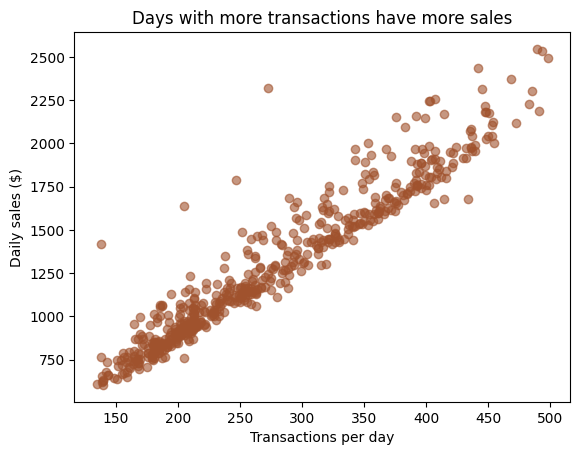

In [117]:
import matplotlib.pyplot as plt
plt.scatter(df["Transactions"], df["Daily_Sales"], alpha=0.6, color="sienna")
plt.title("Days with more transactions have more sales")
plt.xlabel("Transactions per day")
plt.ylabel("Daily sales ($)")
plt.show()


Negative relationship - does a higher coffee share mean a lower tea share?

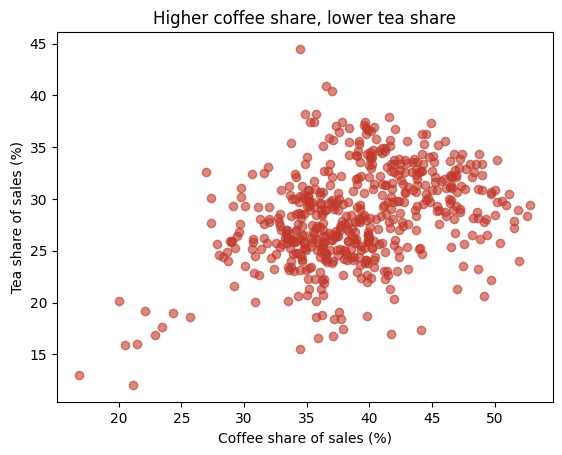

In [118]:
plt.scatter(df["Coffee_Share_Pct"], df["Tea_Share_Pct"], alpha=0.6, color="#C0392B")
plt.title("Higher coffee share, lower tea share")
plt.xlabel("Coffee share of sales (%)")
plt.ylabel("Tea share of sales (%)")
plt.show()


Neutral relationship / no relationship - does the average hour affect the average unit price?

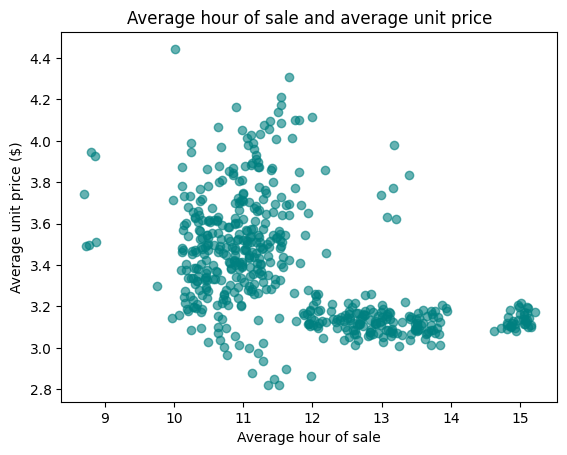

In [119]:
plt.scatter(df["Avg_Hour"], df["Avg_Unit_Price"], alpha=0.6, color="teal")
plt.title("Average hour of sale and average unit price")
plt.xlabel("Average hour of sale")
plt.ylabel("Average unit price ($)")
plt.show()


Correlation coefficient: how strong is the relationship and which direction?

In [120]:
r1 = df["Transactions"].corr(df["Daily_Sales"])
r2 = df["Coffee_Share_Pct"].corr(df["Tea_Share_Pct"])
r3 = df["Avg_Hour"].corr(df["Avg_Unit_Price"])

print("Transactions and sales    :", round(r1, 2))
print("Coffee share and tea share:", round(r2, 2))
print("Avg hour and unit price   :", round(r3, 2))


Transactions and sales    : 0.96
Coffee share and tea share: 0.37
Avg hour and unit price   : -0.49


How are all the key variables related to each other?

In [121]:
corr = df[key_cols].corr().round(2)
corr


,Transactions,Items_Sold,Avg_Unit_Price,Avg_Bill,Coffee_Share_Pct,Morning_Share_Pct,Large_Size_Share_Pct,Unique_Products,Daily_Sales
Transactions,1.00,0.97,0.04,-0.02,-0.02,0.04,-0.01,0.42,0.96
Items_Sold,0.97,1.00,-0.01,0.10,0.03,0.06,-0.04,0.41,0.97
Avg_Unit_Price,0.04,-0.01,1.00,0.53,-0.76,0.55,-0.36,0.68,0.19
Avg_Bill,-0.02,0.10,0.53,1.00,-0.43,0.35,-0.26,0.34,0.26
Coffee_Share_Pct,-0.02,0.03,-0.76,-0.43,1.00,-0.52,0.34,-0.61,-0.14
Morning_Share_Pct,0.04,0.06,0.55,0.35,-0.52,1.00,-0.56,0.72,0.14
Large_Size_Share_Pct,-0.01,-0.04,-0.36,-0.26,0.34,-0.56,1.00,-0.50,-0.09
Unique_Products,0.42,0.41,0.68,0.34,-0.61,0.72,-0.50,1.00,0.52
Daily_Sales,0.96,0.97,0.19,0.26,-0.14,0.14,-0.09,0.52,1.00


HEAT MAP: where are the strong and weak relationships?

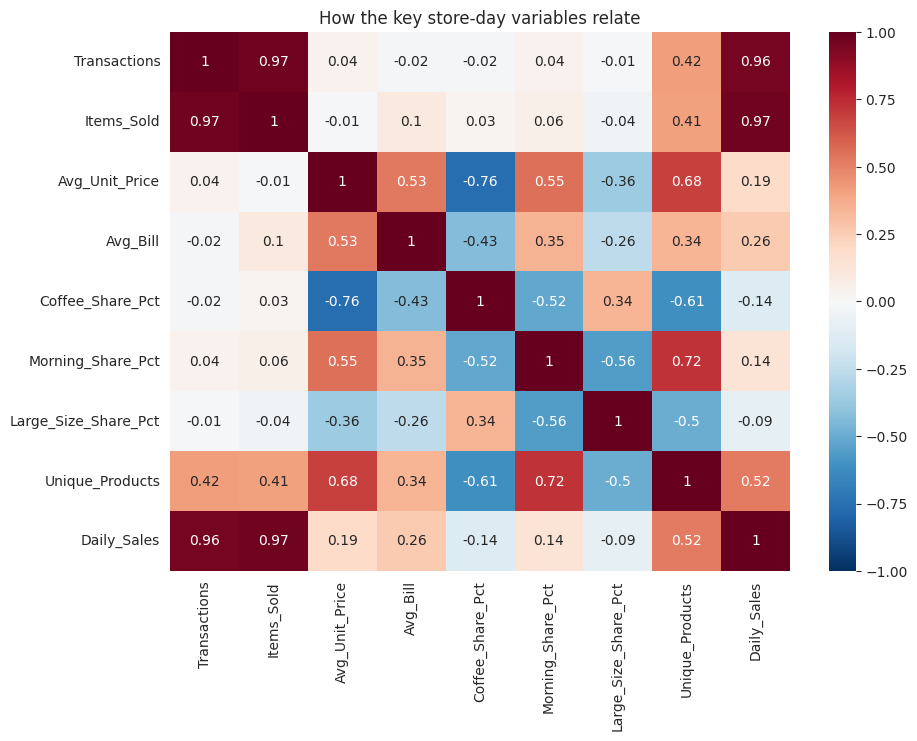

In [122]:
import seaborn as sns
sns.set_style("whitegrid")

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, cmap="RdBu_r", vmin=-1, vmax=1)

plt.title("How the key store-day variables relate")
plt.show()


#STATISTICAL MODELLING - LINEAR REGRESSION

Do more transactions raise sales, and by how much?

In [123]:
import statsmodels.formula.api as smf   # pre-installed in Colab

m_trans = smf.ols("Daily_Sales ~ Transactions", data=df).fit()

print(m_trans.summary().tables[1])
print("R-squared:", round(m_trans.rsquared, 2))

# Interpretation: one extra transaction is associated with the coefficient above
# (in dollars) of extra daily sales. R-squared tells what share of the variation
# in daily sales is explained by transactions. The P>|t| column is the P VALUE:
# below 0.05 means a statistically significant relationship.


                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept        3.9278     17.829      0.220      0.826     -31.095      38.950
Transactions     4.6721      0.062     75.571      0.000       4.551       4.794
R-squared: 0.91


MULTIPLE LINEAR REGRESSION: what is the effect of some variables on daily sales?

In [124]:
m_multi = smf.ols("Daily_Sales ~ Transactions + Avg_Unit_Price + Coffee_Share_Pct", data=df).fit()

print(m_multi.summary().tables[1])
print("R-squared:", round(m_multi.rsquared, 2))


                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept         -716.9592    127.104     -5.641      0.000    -966.639    -467.279
Transactions         4.6430      0.053     87.195      0.000       4.538       4.748
Avg_Unit_Price     219.8749     25.137      8.747      0.000     170.497     269.253
Coffee_Share_Pct    -0.3595      1.268     -0.284      0.777      -2.850       2.131
R-squared: 0.94


#MULTIPLE REGRESSION, MODERATION EFFECT AND PCA

Does the number of products still matter once transactions are held fixed?

In [125]:
m_prod_alone = smf.ols("Daily_Sales ~ Unique_Products", data=df).fit()
m_prod_ctrl = smf.ols("Daily_Sales ~ Unique_Products + Transactions", data=df).fit()

print(m_prod_alone.summary().tables[1])
print("R-squared:", round(m_prod_alone.rsquared, 2))

print(m_prod_ctrl.summary().tables[1])
print("R-squared:", round(m_prod_ctrl.rsquared, 2))

print("Unique products effect alone:", round(m_prod_alone.params["Unique_Products"], 2),
      "| p-value:", round(m_prod_alone.pvalues["Unique_Products"], 3))

print("Unique products effect with Transactions:", round(m_prod_ctrl.params["Unique_Products"], 2),
      "| p-value:", round(m_prod_ctrl.pvalues["Unique_Products"], 3))


                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept        -606.1866    135.997     -4.457      0.000    -873.333    -339.041
Unique_Products    32.3628      2.309     14.016      0.000      27.827      36.898
R-squared: 0.27
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept        -431.0969     42.226    -10.209      0.000    -514.044    -348.150
Unique_Products     8.7844      0.788     11.143      0.000       7.236      10.333
Transactions        4.3850      0.061     71.350      0.000       4.264       4.506
R-squared: 0.93
Unique products effect alone: 32.36 | p-value: 0.0
Unique products effect with Transactions: 8.78 | p-value: 0.0


MODERATION / INTERACTION EFFECT - Step 1: centering of variables (subtract the average)

In [126]:
df["Trans_c"] = df["Transactions"] - df["Transactions"].mean()
df["Price_c"] = df["Avg_Unit_Price"] - df["Avg_Unit_Price"].mean()
df["Coffee_c"] = df["Coffee_Share_Pct"] - df["Coffee_Share_Pct"].mean()
df["Hour_c"] = df["Avg_Hour"] - df["Avg_Hour"].mean()

# A yes or no flag: 1 = Hell's Kitchen store, 0 = other stores
df["Is_HellsKitchen"] = (df["store_location"] == "Hell's Kitchen").astype(int)
df.head()


,transaction_date,store_location,Daily_Sales,Transactions,Items_Sold,Avg_Unit_Price,Avg_Bill,Avg_Hour,Unique_Products,Coffee_Share_Pct,Tea_Share_Pct,Bakery_Share_Pct,Morning_Share_Pct,Large_Size_Share_Pct,Is_Weekend,Trans_c,Price_c,Coffee_c,Hour_c,Is_HellsKitchen
0,2023-01-01,Astoria,868.40,190,277,3.161316,4.570526,15.000000,47,43.965914,32.600184,7.024413,11.578947,35.789474,1,-84.615101,-0.217235,5.072234,3.256864,0
1,2023-01-01,Hell's Kitchen,851.45,184,270,3.177446,4.627446,13.717391,49,50.155617,33.754184,7.663398,28.260870,38.586957,1,-90.615101,-0.201106,11.261937,1.974255,1
2,2023-01-01,Lower Manhattan,788.35,176,255,3.105114,4.479261,11.960227,51,44.555083,30.519439,14.619141,46.590909,30.113636,1,-98.615101,-0.273438,5.661403,0.217091,0
3,2023-01-02,Astoria,925.50,212,301,3.122170,4.365566,14.886792,51,46.126418,31.102107,13.749325,12.264151,32.547170,0,-62.615101,-0.256381,7.232738,3.143656,0
4,2023-01-02,Hell's Kitchen,828.80,195,272,3.072051,4.250256,13.215385,50,48.057432,33.391651,9.833494,36.410256,34.358974,0,-79.615101,-0.306500,9.163752,1.472248,1


Step 2: moderation effect of price level

In [127]:
# Does the effect of transactions on sales depend on how premium the store-day is?
m_mod = smf.ols("Daily_Sales ~ Trans_c * Price_c", data=df).fit()

print(m_mod.summary().tables[1])
print("R-squared:", round(m_mod.rsquared, 2))


                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept        1286.7934      4.685    274.656      0.000    1277.590    1295.997
Trans_c             4.6386      0.053     86.797      0.000       4.534       4.744
Price_c           226.9412     16.390     13.846      0.000     194.745     259.137
Trans_c:Price_c     0.1527      0.182      0.840      0.401      -0.204       0.510
R-squared: 0.94


Step 3: check the moderation effect through a linear model plot

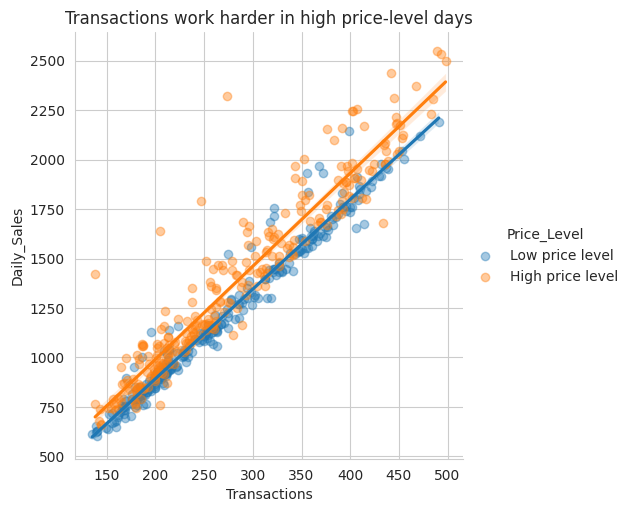

In [128]:
df["Price_Level"] = np.where(df["Avg_Unit_Price"] > df["Avg_Unit_Price"].median(), "High price level", "Low price level")

g = sns.lmplot(data=df, x="Transactions", y="Daily_Sales", hue="Price_Level", height=5, scatter_kws={"alpha": 0.4})

g.set(title="Transactions work harder in high price-level days")

plt.show()


#PRINCIPAL COMPONENT ANALYSIS (PCA)

Group the related variables

In [132]:
groups = {
    "Sales Volume": ["Transactions", "Items_Sold", "Daily_Sales", "Unique_Products"],
    "Morning Menu": ["Morning_Share_Pct", "Avg_Unit_Price", "Unique_Products"],
    "Drink Focus": ["Coffee_Share_Pct", "Tea_Share_Pct", "Large_Size_Share_Pct"],
}

for name, cols in groups.items():
    c = df[cols].corr().values
    average = (c.sum() - len(cols)) / (len(cols) * (len(cols) - 1))  # average correlation inside the group
    print(f"{name}: {len(cols)} variables, average correlation {average:.2f}")

Sales Volume: 4 variables, average correlation 0.71
Morning Menu: 3 variables, average correlation 0.65
Drink Focus: 3 variables, average correlation 0.42


Correlation inside the Sales Volume group

In [133]:
df[["Transactions", "Items_Sold", "Daily_Sales", "Unique_Products"]].corr().round(1)

,Transactions,Items_Sold,Daily_Sales,Unique_Products
Transactions,1.0,1.0,1.0,0.4
Items_Sold,1.0,1.0,1.0,0.4
Daily_Sales,1.0,1.0,1.0,0.5
Unique_Products,0.4,0.4,0.5,1.0


PCA 1 - SALES VOLUME INDEX

In [134]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

cols = groups["Sales Volume"]

# Step A: put every variable on the same scale
scaled = StandardScaler().fit_transform(df[cols])

# Step B: run PCA
pca = PCA()
scores = pca.fit_transform(scaled)

# Step C: how much does each component explain?
names = [f"PC{i+1}" for i in range(len(cols))]
print(pd.Series(pca.explained_variance_ratio_, index=names).round(2))


PC1    0.80
PC2    0.18
PC3    0.01
PC4    0.01
dtype: float64



Step D: the loadings show how much each variable counts in PC1


In [135]:
sign = 1 if pca.components_[0].sum() > 0 else -1  # make sure a higher score means more volume

print(pd.Series(pca.components_[0] * sign, index=cols).round(2))


Transactions       0.54
Items_Sold         0.54
Daily_Sales        0.55
Unique_Products    0.33
dtype: float64


Step E: turn PC1 into an index from 0 to 100

In [136]:
raw_index = scores[:, 0] * sign

df["Volume_Index"] = (raw_index - raw_index.min()) / (raw_index.max() - raw_index.min()) * 100

variance_explained = {"Volume_Index": round(pca.explained_variance_ratio_[0] * 100)}

print(df[["transaction_date", "store_location", "Volume_Index"]].sort_values("Volume_Index").head(5).round(1))
df.head()


    transaction_date   store_location  Volume_Index
85        2023-01-29   Hell's Kitchen           0.0
11        2023-01-04  Lower Manhattan           3.0
108       2023-02-06          Astoria           4.0
129       2023-02-13          Astoria           4.1
86        2023-01-29  Lower Manhattan           4.2


,transaction_date,store_location,Daily_Sales,Transactions,Items_Sold,Avg_Unit_Price,Avg_Bill,Avg_Hour,Unique_Products,Coffee_Share_Pct,...,Morning_Share_Pct,Large_Size_Share_Pct,Is_Weekend,Trans_c,Price_c,Coffee_c,Hour_c,Is_HellsKitchen,Price_Level,Volume_Index
0,2023-01-01,Astoria,868.40,190,277,3.161316,4.570526,15.000000,47,43.965914,...,11.578947,35.789474,1,-84.615101,-0.217235,5.072234,3.256864,0,Low price level,13.870696
1,2023-01-01,Hell's Kitchen,851.45,184,270,3.177446,4.627446,13.717391,49,50.155617,...,28.260870,38.586957,1,-90.615101,-0.201106,11.261937,1.974255,1,Low price level,13.981307
2,2023-01-01,Lower Manhattan,788.35,176,255,3.105114,4.479261,11.960227,51,44.555083,...,46.590909,30.113636,1,-98.615101,-0.273438,5.661403,0.217091,0,Low price level,12.832203
3,2023-01-02,Astoria,925.50,212,301,3.122170,4.365566,14.886792,51,46.126418,...,12.264151,32.547170,0,-62.615101,-0.256381,7.232738,3.143656,0,Low price level,19.911074
4,2023-01-02,Hell's Kitchen,828.80,195,272,3.072051,4.250256,13.215385,50,48.057432,...,36.410256,34.358974,0,-79.615101,-0.306500,9.163752,1.472248,1,Low price level,15.128772


PCA 2 - MORNING MENU INDEX

In [138]:
def make_index(columns, index_name):
    scaled = StandardScaler().fit_transform(df[columns])
    pca = PCA().fit(scaled)
    scores = pca.transform(scaled)[:, 0]

    sign = 1 if pca.components_[0].sum() > 0 else -1
    scores = scores * sign

    df[index_name] = (scores - scores.min()) / (scores.max() - scores.min()) * 100
    variance_explained[index_name] = round(pca.explained_variance_ratio_[0] * 100)

    print("Variance explained by PC1:", variance_explained[index_name], "%")
    print(pd.Series(pca.components_[0] * sign, index=columns).round(2))

make_index(groups["Morning Menu"], "Morning_Index")
df.head()


Variance explained by PC1: 77 %
Morning_Share_Pct    0.57
Avg_Unit_Price       0.56
Unique_Products      0.61
dtype: float64


,transaction_date,store_location,Daily_Sales,Transactions,Items_Sold,Avg_Unit_Price,Avg_Bill,Avg_Hour,Unique_Products,Coffee_Share_Pct,...,Large_Size_Share_Pct,Is_Weekend,Trans_c,Price_c,Coffee_c,Hour_c,Is_HellsKitchen,Price_Level,Volume_Index,Morning_Index
0,2023-01-01,Astoria,868.40,190,277,3.161316,4.570526,15.000000,47,43.965914,...,35.789474,1,-84.615101,-0.217235,5.072234,3.256864,0,Low price level,13.870696,2.418986
1,2023-01-01,Hell's Kitchen,851.45,184,270,3.177446,4.627446,13.717391,49,50.155617,...,38.586957,1,-90.615101,-0.201106,11.261937,1.974255,1,Low price level,13.981307,14.354148
2,2023-01-01,Lower Manhattan,788.35,176,255,3.105114,4.479261,11.960227,51,44.555083,...,30.113636,1,-98.615101,-0.273438,5.661403,0.217091,0,Low price level,12.832203,24.347597
3,2023-01-02,Astoria,925.50,212,301,3.122170,4.365566,14.886792,51,46.126418,...,32.547170,0,-62.615101,-0.256381,7.232738,3.143656,0,Low price level,19.911074,7.286828
4,2023-01-02,Hell's Kitchen,828.80,195,272,3.072051,4.250256,13.215385,50,48.057432,...,34.358974,0,-79.615101,-0.306500,9.163752,1.472248,1,Low price level,15.128772,16.649429


PCA 3 - DRINK FOCUS INDEX

In [139]:
make_index(groups["Drink Focus"], "Drink_Index")
df.head()


Variance explained by PC1: 61 %
Coffee_Share_Pct        0.51
Tea_Share_Pct           0.61
Large_Size_Share_Pct    0.60
dtype: float64


,transaction_date,store_location,Daily_Sales,Transactions,Items_Sold,Avg_Unit_Price,Avg_Bill,Avg_Hour,Unique_Products,Coffee_Share_Pct,...,Is_Weekend,Trans_c,Price_c,Coffee_c,Hour_c,Is_HellsKitchen,Price_Level,Volume_Index,Morning_Index,Drink_Index
0,2023-01-01,Astoria,868.40,190,277,3.161316,4.570526,15.000000,47,43.965914,...,1,-84.615101,-0.217235,5.072234,3.256864,0,Low price level,13.870696,2.418986,85.178790
1,2023-01-01,Hell's Kitchen,851.45,184,270,3.177446,4.627446,13.717391,49,50.155617,...,1,-90.615101,-0.201106,11.261937,1.974255,1,Low price level,13.981307,14.354148,99.633429
2,2023-01-01,Lower Manhattan,788.35,176,255,3.105114,4.479261,11.960227,51,44.555083,...,1,-98.615101,-0.273438,5.661403,0.217091,0,Low price level,12.832203,24.347597,71.256275
3,2023-01-02,Astoria,925.50,212,301,3.122170,4.365566,14.886792,51,46.126418,...,0,-62.615101,-0.256381,7.232738,3.143656,0,Low price level,19.911074,7.286828,78.770115
4,2023-01-02,Hell's Kitchen,828.80,195,272,3.072051,4.250256,13.215385,50,48.057432,...,0,-79.615101,-0.306500,9.163752,1.472248,1,Low price level,15.128772,16.649429,88.411881


Checking correlation for all the indexes

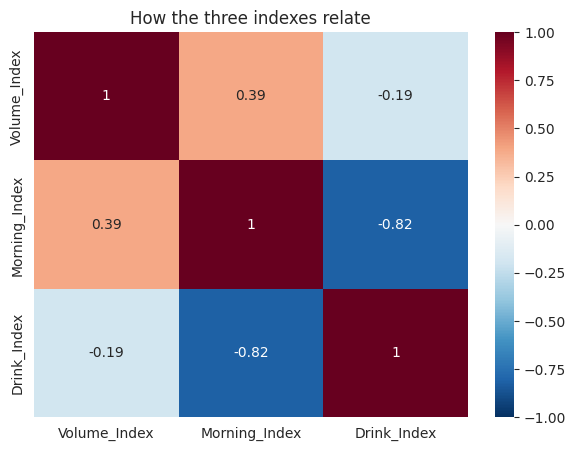

In [140]:
index_cols = ["Volume_Index", "Morning_Index", "Drink_Index"]

plt.figure(figsize=(7, 5))
sns.heatmap(df[index_cols].corr().round(2), annot=True, cmap="RdBu_r", vmin=-1, vmax=1)

plt.title("How the three indexes relate")
plt.show()
